# Assignment 07 — EC: reading customer reviews with a 5-layer RNN and a 5-layer LSTM

Every online shop collects free-text reviews, and nobody has time to read thousands of them. A program that reads a review and tells whether the customer was satisfied would let a shop spot unhappy customers and problem products automatically. This notebook builds such a program with the two models the assignment asks for, a **recurrent neural network (RNN)** and a **long short-term memory network (LSTM)**, and then asks the question the whole assignment is about: *does the LSTM's extra machinery buy anything over a plain RNN on real text?*

**Data.** *Amazon Reviews: Unlocked Mobile Phones* (PromptCloud, from Kaggle) contains 413,840 reviews of about 4,400 unlocked phones sold on Amazon. Each review has a 1–5 star rating and a free-text comment, and the whole file is 132 MB.

**Task.** Read the comment and decide whether the customer is **positive** (4–5 stars) or **negative** (1–2 stars). Three-star reviews are left out because they are genuinely ambiguous ("it's okay") and would only add label noise. This is a binary classification problem.

**Why recurrent networks.** A review is not a bag of independent words, it is a sequence: "not good" and "good, not bad" use almost the same words with opposite meaning. An RNN reads the review one word at a time and keeps a running memory of what it has read; an LSTM adds a gated memory that can hold on to information for much longer. Reviews of up to 100 words, in which the complaint may come at the end after a polite opening, are a natural test of exactly this difference.

**Models.** The same architecture four times, {5-layer RNN, 5-layer LSTM} × {Keras, PyTorch}: word ids → embedding (64 numbers per word) → five recurrent layers of 64 units → the last state → one output unit with a sigmoid. The run IDs are `EC-TF-RNN`, `EC-TF-LSTM`, `EC-PT-RNN` and `EC-PT-LSTM`. How each network is built from elementary functions is derived step by step in `00_rnn_lstm_concepts.ipynb`; here we simply use them.

**Plan of the notebook.** First we explore the data and decide what to clean (§2), turn text into numbers (§3), set baselines that any network must beat (§4), train the four networks (§5–§6), compare them from several angles (§7) and draw the conclusion (§8).

## 1. Setup

A comparison is only fair if everything except the thing being compared is identical. If the LSTM beat the RNN but the two had been trained with different optimizers, we could not tell whether the architecture or the optimizer made the difference. So every run uses one random seed (42) for Python, NumPy, TensorFlow and PyTorch, the same data arrays, the same architecture shape and the same training recipe:

- **Adam, learning rate $10^{-3}$.** Training means nudging every weight a little in the direction that lowers the loss, and Adam is a standard way of choosing the size of each nudge. It keeps a running average of every weight's recent gradient and of its square, so weights with steady gradients move confidently and weights with noisy gradients move cautiously. The learning rate scales all the steps.
- **Gradient clipping at norm 1.** In a recurrent network a single bad batch can produce an enormous gradient that throws the weights far off. Clipping rescales the gradient so that its length never exceeds 1; it only acts in these rare emergencies.
- **Batch size 256.** The network looks at 256 reviews, computes the average loss on them and makes one update. Larger batches give smoother updates, smaller ones more updates per pass over the data; 256 is a common compromise that also keeps a CPU busy.
- **At most 10 epochs with early stopping (patience 2).** An epoch is one pass over all training reviews. After each epoch we measure the loss on validation reviews that the network never trains on. A network with more than a million parameters will sooner or later start to memorise its training reviews, and then the validation loss rises while the training loss keeps falling. Early stopping watches for this: if the validation loss has not improved for two epochs we stop and keep the weights of the best epoch.

In [1]:
import os, re, time, json, random, collections, warnings
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA = Path("../data")
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
IMG = Path("../../report/images"); IMG.mkdir(parents=True, exist_ok=True)

VOCAB, MAXLEN, EMB, H, LAYERS = 20_000, 100, 64, 64, 5
BATCH, LR, CLIP = 256, 1e-3, 1.0
EPOCHS, PATIENCE = 10, 2
# ---- shared look of every chart: warm paper, no boxes or grid lines, direct labels instead of legends ----
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle, Rectangle, Polygon
C = dict(rnn="#12a39a", lstm="#d6336c", pos="#dd9a00", neg="#5a4bd1", ink="#1f2430", mute="#8c8a85", rule="#e4dfd5", paper="#fbf8f2",
         base="#8c8a85", faint="#ddd7ca", teal_l="#cfe9e6", mag_l="#f6cddb", amb_l="#f7e2b0", ind_l="#d5d0f3")
SEQ = LinearSegmentedColormap.from_list("seq", ["#f3efe6", "#a8dcd5", "#12a39a", "#0a5c63"])      # one hue, light -> dark
DIV = LinearSegmentedColormap.from_list("div", ["#5a4bd1", "#f3efe6", "#d6336c"])                  # two hues around a neutral middle
DUO = LinearSegmentedColormap.from_list("duo", [C["rnn"], "#f3efe6", C["lstm"]])                 # teal = RNN side, magenta = LSTM side
CLS = LinearSegmentedColormap.from_list("cls", [C["pos"], "#f3efe6", C["neg"]])                  # amber = positive side, indigo = negative side
plt.rcParams.update({
    "figure.facecolor": C["paper"], "axes.facecolor": C["paper"], "savefig.facecolor": C["paper"], "figure.dpi": 100, "savefig.dpi": 170,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "text.color": C["ink"], "axes.labelcolor": C["mute"],
    "xtick.color": C["mute"], "ytick.color": C["mute"], "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.grid": False, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False})

def headline(fig, title, sub=""):
    """big serif title and a grey sub-title in the top-left corner of the figure"""
    h = fig.get_figheight()
    fig.text(0.004, 1 - 0.05 / h, title, fontsize=15, fontweight="bold", family=["Georgia", "DejaVu Serif"], va="top")
    if sub: fig.text(0.004, 1 - 0.40 / h, sub, fontsize=9.5, color=C["mute"], va="top")

def finish(fig, name, top_in=1.1):
    h = fig.get_figheight(); fig.subplots_adjust(left=0.06, right=0.985, bottom=0.11, top=1 - top_in / h)
    plt.savefig(IMG / f"{name}.png", bbox_inches="tight"); plt.show()

def style(run_id):
    """colour = architecture, line style = framework (the same in every chart)"""
    return dict(color=C["rnn"] if run_id.endswith("RNN") else C["lstm"], ls="-" if "-TF-" in run_id else "--")

def mk(run_id): return "o" if "-TF-" in run_id else "s"        # circle = TensorFlow, square = PyTorch

### Hyperparameters

A *hyperparameter* is a setting we choose before training, as opposed to the weights that training finds. Each value below has a reason; some of the reasons only become visible in the data exploration of §2–§3, which is why the table points forward.

| Name | Value | Meaning and reason |
|---|---|---|
| vocabulary | 20,000 words | the most frequent words of the **training** reviews; every other word becomes `<unk>`. §3 shows that these words make up 99.3 % of all word occurrences |
| sequence length $T$ | 100 words | longer reviews are cut. 88.8 % of the reviews fit completely, and a recurrent network needs one computation step per word, so $T$ cannot be unlimited |
| embedding | 64 | each word id becomes a learned vector of 64 numbers (explained in §5) |
| hidden units $H$ | 64 per layer | the size of each layer's memory; a modest size keeps the five-layer stack trainable on a CPU |
| layers $L$ | 5 | required by the assignment; layer $l$ reads the states of layer $l-1$ |
| output | Dense(1) + sigmoid | one number squashed into $(0,1)$: $P(\text{positive})$ |
| loss | binary cross-entropy | $-[y\ln p+(1-y)\ln(1-p)]$. If the review is positive ($y=1$) and the model says $p=0.9$ the loss is $0.105$; if it says $p=0.1$ the loss is $2.30$. Confident mistakes are punished hard |
| optimizer | Adam, $10^{-3}$, clip-norm 1 | see §1 |
| batch / epochs | 256 / at most 10, early stopping with patience 2 | see §1 |

## 2. Data

Before building anything we look at what the file actually contains. The first rows and the column types printed below show six columns: the product name and the brand name (text), the price (a decimal number), the **star rating** (a whole number from 1 to 5), the **review text** (a string) and the number of helpfulness votes the review received (a decimal, because missing values force pandas to store the column as a float). Only two columns matter for our task: the text is the input and the rating is where the label will come from. Product, brand and price might let a model guess that cheap phones get worse reviews, but that would not be *reading* the review, so we leave them out.

Two questions decide how we clean the data. How many reviews have no text at all? And is every row in the file really a different review? The counts printed below the table answer both.

In [2]:
raw = pd.read_csv(DATA / "Amazon_Unlocked_Mobile.csv")
print(f"The raw file has {raw.shape[0]:,} rows and {raw.shape[1]} columns. Its first three rows:")
display(raw.head(3))
print("Data type of each column:")
display(raw.dtypes.astype(str).rename("type").to_frame().T)
print(f"{raw.Reviews.isna().sum()} reviews have no text, and {raw.Reviews.duplicated().sum():,} rows repeat a review text that appeared earlier in the file.")

The raw file has 413,840 rows and 6 columns. Its first three rows:


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0


Data type of each column:


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
type,str,str,float64,int64,str,float64


70 reviews have no text, and 251,349 rows repeat a review text that appeared earlier in the file.


**What the counts tell us.** Only 70 reviews have no text, which is nothing among 413,840 rows, so those can simply be dropped. The surprise is the duplicates: 251,349 rows repeat a review text that already appeared earlier in the file. The reason is how the data was collected. A phone is often sold in several variants (colours, storage sizes, carriers) that each have their own listing, and the shop's page shows the reviews of the whole product family under every variant, so each review was collected once per variant.

This matters for more than tidiness. If a review appears five times and we split the file randomly into training and test reviews, some copies land in the training set and others in the test set, and the network is then "tested" on text it has already seen. Its test accuracy would measure memory, not understanding. So we keep one copy of each text *before* splitting. The funnel in the next chart shows what survives.

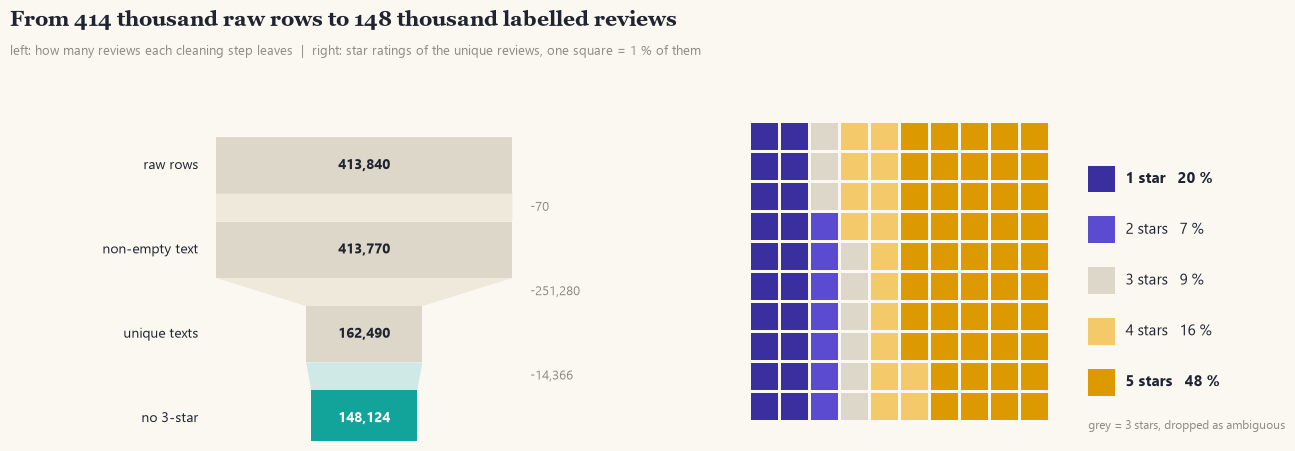

After removing the 3-star reviews we keep 148,124 reviews, and 70.1% of them are positive.


In [3]:
n_raw = len(raw)
nonempty = raw.dropna(subset=["Reviews"])
unique = nonempty.drop_duplicates(subset=["Reviews"]).copy()
df = unique[unique.Rating != 3].copy()
df["y"] = (df.Rating >= 4).astype(int)

fig = plt.figure(figsize=(13, 4.9)); gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.05])
# left: the cleaning funnel, each stage is a bar whose width is the number of reviews that are left
a = fig.add_subplot(gs[0]); a.axis("off")
steps = [("raw rows", n_raw), ("non-empty text", len(nonempty)), ("unique texts", len(unique)), ("no 3-star", len(df))]
w = np.array([n for _, n in steps]) / n_raw
for i, ((name, n), wi) in enumerate(zip(steps, w)):
    y = -1.5 * i
    if i:
        wp = w[i - 1]
        a.add_patch(Polygon([(-wp / 2, y + 1.0), (wp / 2, y + 1.0), (wi / 2, y + 0.5), (-wi / 2, y + 0.5)], fc=C["teal_l"] if i == 3 else "#efe9dc", ec="none"))
        a.text(0.56, y + 0.75, f"-{steps[i - 1][1] - n:,}", color=C["mute"], fontsize=9, va="center")
    a.add_patch(Rectangle((-wi / 2, y - 0.5), wi, 1.0, fc=C["rnn"] if i == 3 else C["faint"], ec="none"))
    a.text(0, y, f"{n:,}", ha="center", va="center", fontweight="bold", color="white" if i == 3 else C["ink"])
    a.text(-0.56, y, name, ha="right", va="center")
a.set_xlim(-0.95, 0.85); a.set_ylim(-4.9, 0.9)

# right: a waffle, one square = 1 % of the unique reviews, filled star by star
b = fig.add_subplot(gs[1]); b.axis("off"); b.set_aspect("equal")
share = unique.Rating.value_counts(normalize=True).sort_index() * 100
cnt = np.floor(share.values).astype(int)
for j in np.argsort(-(share.values - cnt))[: 100 - cnt.sum()]: cnt[j] += 1          # largest remainder: exactly 100 squares
star_col = ["#3a2f9e", C["neg"], C["faint"], "#f3c969", C["pos"]]
k = 0
for c, col in zip(cnt, star_col):
    for _ in range(c):
        b.add_patch(Rectangle(((k // 10) * 1.12, (k % 10) * 1.12), 1, 1, fc=col, ec="none")); k += 1
for i, (star, col) in enumerate(zip(share.index, star_col)):
    yy = 9.0 - 1.9 * i
    b.add_patch(Rectangle((12.6, yy - 0.5), 1, 1, fc=col, ec="none"))
    b.text(14.0, yy, f"{star} star{'s' if star > 1 else ''}   {share[star]:.0f} %", va="center", fontsize=11, fontweight="bold" if star in (1, 5) else "normal")
b.text(12.6, -0.35, "grey = 3 stars, dropped as ambiguous", fontsize=8.5, color=C["mute"])
b.set_xlim(-0.5, 19.5); b.set_ylim(-0.8, 11.4)
headline(fig, "From 414 thousand raw rows to 148 thousand labelled reviews", "left: how many reviews each cleaning step leaves  |  right: star ratings of the unique reviews, one square = 1 % of them")
finish(fig, "EC_ratings")
print(f"After removing the 3-star reviews we keep {len(df):,} reviews, and {df.y.mean():.1%} of them are positive.")

**Reading the charts.** The funnel shows how drastic the duplicate removal is: of the 413,770 rows with text only 162,490, about 39 %, are different reviews, so most of the file was repetition. Dropping the 3-star reviews removes another 14,366 and leaves 148,124 labelled reviews, which is still plenty for a model with over a million parameters.

The waffle on the right counts the unique reviews by star rating, one square per percent of the reviews. Looking at it, we can see that customers give 5 stars almost half of the time (48 %), that 1 star is the second most common rating (20 %), and that the middle ratings are rare (2 stars 7 %, 3 stars 9 %, 4 stars 16 %). People tend to write a review when they are delighted or angry, not when something is merely fine. Once the 3-star reviews are removed, 70 % of the remaining reviews are positive. That has a practical consequence: a "model" that answers *positive* for every review is already right 70 % of the time, so **accuracy alone would flatter a lazy model**. We therefore also report the F1 score of the negative class, the macro-averaged F1 score and the ROC-AUC (all defined in §3), which punish a model that ignores the minority class.

### Review length

A recurrent network reads one word per step, so the number of words in a review is the number of steps the network has to run, and the number of steps it has to remember across. Length therefore decides two things at once: how long the computation takes, and how hard the memory task is.

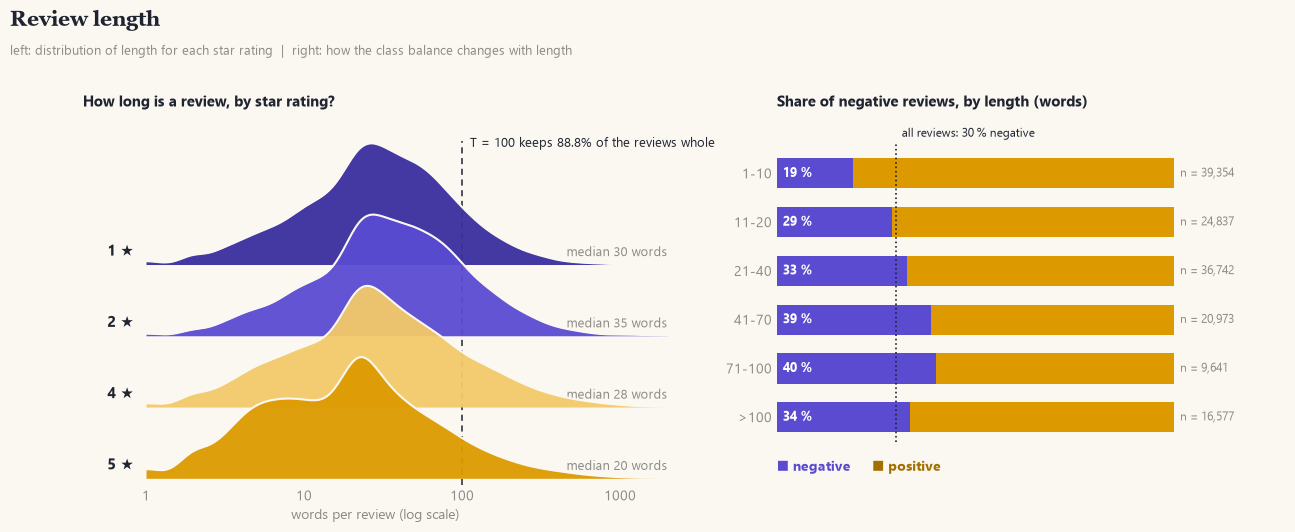

Length of a review in words (median, upper quartile, longest), by class:
           50%   75%     max
y                           
negative  31.0  62.0  4815.0
positive  21.0  46.0  5313.0
88.8% of the reviews have at most 100 words, so cutting at T = 100 leaves them untouched.


In [4]:
from scipy.stats import gaussian_kde
df["n_words"] = df.Reviews.str.split().str.len()
cover = (df.n_words <= MAXLEN).mean()
fig = plt.figure(figsize=(13, 5.4)); gs = fig.add_gridspec(1, 2, width_ratios=[1.15, 1])

a = fig.add_subplot(gs[0]); grid = np.linspace(0, 3.3, 300); rng = np.random.default_rng(0)
stars = [5, 4, 2, 1]; fill = {5: C["pos"], 4: "#f3c969", 2: C["neg"], 1: "#3a2f9e"}
for row, s in enumerate(stars):
    lw_ = np.log10(df.n_words[df.Rating == s].clip(lower=1).values)
    d = gaussian_kde(rng.choice(lw_, size=min(20000, len(lw_)), replace=False), bw_method=0.18)(grid); d = d / d.max() * 1.7
    a.fill_between(grid, row, row + d, color=fill[s], alpha=0.95, lw=0, zorder=10 - row)
    a.plot(grid, row + d, color=C["paper"], lw=1.5, zorder=10 - row)
    a.text(-0.08, row + 0.08, f"{s} ★", ha="right", va="bottom", fontsize=11, fontweight="bold")
    a.text(3.3, row + 0.08, f"median {np.median(df.n_words[df.Rating == s]):.0f} words", ha="right", va="bottom", fontsize=9, color=C["mute"])
a.axvline(np.log10(MAXLEN), color=C["ink"], ls=(0, (4, 3)), lw=1.1, ymax=0.93)
a.text(np.log10(MAXLEN) + 0.05, 4.65, f"T = {MAXLEN} keeps {cover:.1%} of the reviews whole", fontsize=9.5)
a.set_xticks([0, 1, 2, 3], ["1", "10", "100", "1000"]); a.set_yticks([]); a.set_xlim(-0.4, 3.3); a.set_ylim(-0.1, 5.1)
a.set_xlabel("words per review (log scale)"); a.set_title("How long is a review, by star rating?")

b = fig.add_subplot(gs[1])
bins = [0, 10, 20, 40, 70, 100, 100_000]; names = ["1-10", "11-20", "21-40", "41-70", "71-100", ">100"]
bucket = pd.cut(df.n_words, bins, labels=names)
neg_share = (1 - df.y).groupby(bucket).mean().values; n_b = df.groupby(bucket).size().values
yy = np.arange(len(names))[::-1]
b.barh(yy, 100 * neg_share, color=C["neg"], height=0.62); b.barh(yy, 100 * (1 - neg_share), left=100 * neg_share, color=C["pos"], height=0.62)
for y_, ns_, nb_ in zip(yy, neg_share, n_b):
    b.text(1.5, y_, f"{100 * ns_:.0f} %", color="white", va="center", fontsize=9.5, fontweight="bold")
    b.text(101.5, y_, f"n = {nb_:,}", va="center", fontsize=8.5, color=C["mute"])
ov = 100 * (1 - df.y.mean())
b.plot([ov, ov], [-0.5, 5.6], color=C["ink"], lw=1.2, ls=":"); b.text(ov + 1.5, 5.75, f"all reviews: {ov:.0f} % negative", ha="left", fontsize=8.5)
b.text(0, -1.1, "■ negative", color=C["neg"], fontweight="bold"); b.text(24, -1.1, "■ positive", color="#a36f00", fontweight="bold")
b.set_yticks(yy, names); b.set_xticks([]); b.set_xlim(0, 128); b.set_ylim(-1.4, 6.2); b.set_title("Share of negative reviews, by length (words)")
headline(fig, "Review length", "left: distribution of length for each star rating  |  right: how the class balance changes with length")
finish(fig, "EC_length")
print("Length of a review in words (median, upper quartile, longest), by class:")
print(df.groupby("y").n_words.describe()[["50%", "75%", "max"]].rename(index={0: "negative", 1: "positive"}))
print(f"{cover:.1%} of the reviews have at most {MAXLEN} words, so cutting at T = {MAXLEN} leaves them untouched.")

**Reading the length charts.** The ridgelines show that review length varies enormously. The typical review is short (the median over all reviews is 24 words, the mean 49 because a few reviews have thousands of words), but there is a long tail, which is why the axis is logarithmic: each tick is ten times the previous one. The medians climb as the rating gets worse: 5-star reviews have a median of 20 words, 4-star reviews 28, 1-star reviews 30 and 2-star reviews 35. Satisfied customers write "great phone, works perfectly" and move on; unhappy customers explain what went wrong and what they tried.

The bars on the right make the same point from the other side. Among the shortest reviews (1–10 words) only 19 % are negative, while among reviews of 41–100 words about 40 % are, against 30 % overall. This is an important hint for the experiment: negative evidence is spread over more words, so a model with a longer memory has a real chance to help on exactly the reviews that matter most to a shop. (Above 100 words the share drops again to 34 %, but those reviews are cut at $T=100$, so the network only sees their first 100 words.)

The dashed line in the ridgeline marks $T=100$. The choice of $T$ is a trade-off: a larger $T$ keeps more of the long reviews but makes every training step slower (the steps of a recurrence cannot be computed in parallel) and gives the network a longer sequence to remember. With $T=100$ about 89 % of the reviews fit completely, and for the other 11 % we keep the first 100 words, a limitation we return to in the conclusion.

### Which words separate the classes?

Before any neural network we can ask a simpler question: are there words that give a review away? For every word we compare the share of positive reviews that contain it with the share of negative reviews that contain it. If both shares are equal the word says nothing and sits on the dashed diagonal; the further a word lies from the diagonal, the better it separates the classes. A word is counted once per review, so a customer who writes "refund refund refund" does not outweigh the others.

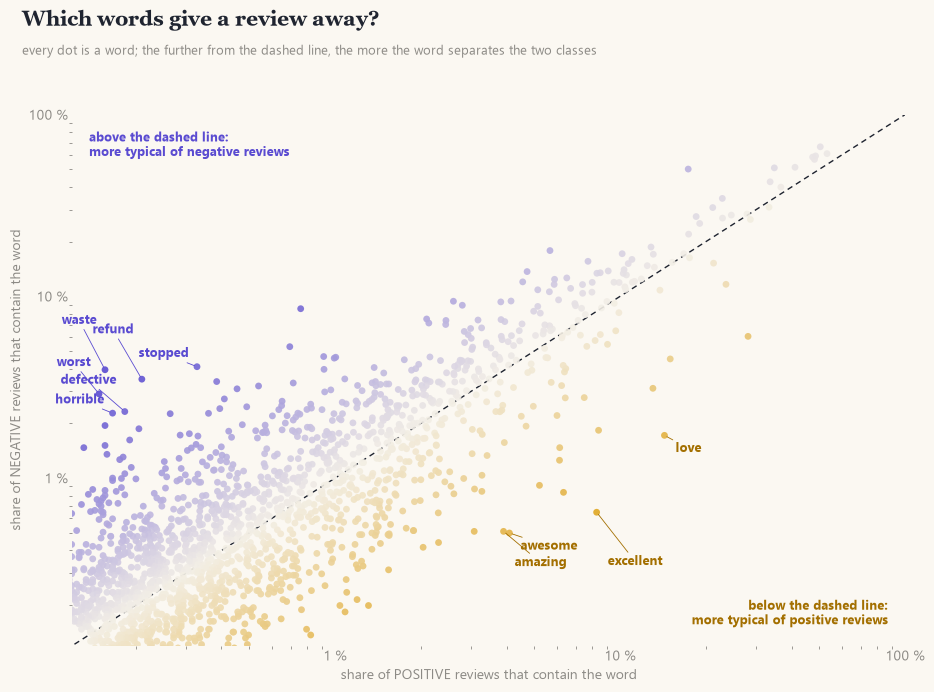

Words that most strongly signal a negative review (and how many times more often they appear there): waste (25.3x), worst (19.6x), refund (16.7x), junk (15.1x), horrible (13.7x), defective (12.7x)


In [5]:
def tokenize(text):
    """lower-case, keep letters, digits and apostrophes: "Don't buy!!" -> ["don't", "buy"]"""
    return re.findall(r"[a-z0-9']+", text.lower())

pos_c, neg_c = collections.Counter(), collections.Counter()
for text, y in zip(df.Reviews.values[:60_000], df.y.values[:60_000]):
    (pos_c if y else neg_c).update(set(tokenize(text)))            # document frequency: each word counted once per review
n_pos, n_neg = (df.y.values[:60_000] == 1).sum(), (df.y.values[:60_000] == 0).sum()
words = [w for w, c in (pos_c + neg_c).most_common(4000) if c >= 80]
fp = np.array([(pos_c[w] + 0.5) / n_pos for w in words]); fn = np.array([(neg_c[w] + 0.5) / n_neg for w in words])
lo = pd.Series(np.log(fn / fp), index=words)                      # > 0: the word is more typical of negative reviews

fig, ax = plt.subplots(figsize=(9, 7.2))
ax.plot([1e-3, 1], [1e-3, 1], color=C["ink"], lw=1, ls=(0, (4, 3)), zorder=1)
ax.scatter(fp, fn, c=lo.values, cmap=CLS, vmin=-3, vmax=3, s=24, edgecolor="none", alpha=0.9, zorder=2)
common = lo[[w for w in words if pos_c[w] + neg_c[w] >= 300]].sort_values()
for i, w in enumerate(sorted(common.tail(7).index, key=lambda q: fp[words.index(q)])):
    ax.annotate(w, (fp[words.index(w)], fn[words.index(w)]), xytext=(-6, 7 + 13 * (i % 3)), textcoords="offset points", ha="right", fontsize=9.5, color=C["neg"], fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=C["neg"], lw=0.6, shrinkA=0, shrinkB=2))
for i, w in enumerate(sorted(common.head(7).index, key=lambda q: fn[words.index(q)])):
    ax.annotate(w, (fp[words.index(w)], fn[words.index(w)]), xytext=(8, -12 - 13 * (i % 3)), textcoords="offset points", ha="left", fontsize=9.5, color="#a36f00", fontweight="bold",
                arrowprops=dict(arrowstyle="-", color="#a36f00", lw=0.6, shrinkA=0, shrinkB=2))
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1.2e-3, 1); ax.set_ylim(1.2e-3, 1)
for axis in (ax.xaxis, ax.yaxis): axis.set_major_formatter(lambda v, _: f"{100 * v:g} %")
ax.set_xlabel("share of POSITIVE reviews that contain the word"); ax.set_ylabel("share of NEGATIVE reviews that contain the word")
ax.text(0.02, 0.97, "above the dashed line:\nmore typical of negative reviews", transform=ax.transAxes, va="top", color=C["neg"], fontweight="bold", fontsize=9.5)
ax.text(0.98, 0.04, "below the dashed line:\nmore typical of positive reviews", transform=ax.transAxes, ha="right", color="#a36f00", fontweight="bold", fontsize=9.5)
headline(fig, "Which words give a review away?", "every dot is a word; the further from the dashed line, the more the word separates the two classes")
finish(fig, "EC_vocab")
print("Words that most strongly signal a negative review (and how many times more often they appear there):", ", ".join(f"{w} ({np.exp(v):.1f}x)" for w, v in common.tail(6)[::-1].items()))

**Reading the word scatter.** The words above the diagonal are typical of negative reviews, and they are exactly what an angry customer says: *waste, worst, refund, junk, horrible, defective, stopped, return, repair, freezes, useless*. These are words about a product that broke or has to be sent back. The words below the diagonal belong to satisfied customers: *excellent, love, perfect, amazing, awesome, fantastic, fits*. Even misspellings such as *excelente* and *excelent* are strong positive signals, which tells us that the vocabulary should be built from the data itself and not from a dictionary.

One word deserves a second look: *complaints* is more typical of **positive** reviews. It comes from phrases like "no complaints", where the negation turns the word around. A method that counts words independently cannot see this, while a model that reads the words in order can; this is the kind of case in which we expect recurrent networks to have an advantage. It also warns us not to expect too much: so many of the signal words are as unambiguous as *refund* and *excellent* that a method that merely counts words will already be strong. That is exactly what the baseline of §4 tests.

## 3. From text to numbers, step by step

A neural network can only multiply numbers, so a review first has to become a row of numbers. We do it in four steps and follow one real review through all of them.

1. **Tokenize**: split the text into lower-case words (tokens). Lower-casing makes "Great" and "great" one word, and keeping apostrophes keeps "don't" in one piece.
2. **Build a vocabulary**: give every frequent word a whole number, its id. The 20,000 most frequent words of the *training* reviews get ids 2, 3, 4, ... in order of frequency. Id 1 is reserved for `<unk>` ("unknown"), which replaces every rarer word, and id 0 is the padding symbol. The vocabulary has to be limited because every word costs 64 learned numbers (§5), and words that occur only once or twice give the network nothing to learn from.
3. **Encode**: replace each word by its id.
4. **Pad or truncate to $T=100$**: the network is fed a rectangular table, so every review needs exactly 100 entries. Shorter reviews are filled with zeros, longer ones are cut after 100 words. We put the zeros **in front** (pre-padding): a recurrent network reads from left to right and what we classify is its final state $h_T$, so it is better that the last thing it reads is a real word and not a long run of zeros that it would have to remember through.

**Split before building the vocabulary.** The reviews are divided into 70 % training, 15 % validation and 15 % test reviews, stratified by label so that each part has the same share of positive reviews. Only then is the vocabulary built, from the training part alone. If it were built from all reviews, words that occur only in the test set would receive ids, and the test set would have leaked into the setup of the model; this way the model meets such words as `<unk>`, exactly as it would meet new words in reviews after deployment. The three parts have different jobs: the *training* reviews are what the network learns from, the *validation* reviews decide when to stop, and the *test* reviews are used once, for the final scores.

In [6]:
idx = np.arange(len(df))
i_tr, i_tmp = train_test_split(idx, test_size=0.30, stratify=df.y, random_state=SEED)
i_va, i_te = train_test_split(i_tmp, test_size=0.50, stratify=df.y.values[i_tmp], random_state=SEED)
texts, y_all = df.Reviews.values, df.y.values.astype("float32")
print(f"Split: {len(i_tr):,} training, {len(i_va):,} validation and {len(i_te):,} test reviews.")

counts = collections.Counter(w for t in texts[i_tr] for w in tokenize(t))
itos = ["<pad>", "<unk>"] + [w for w, _ in counts.most_common(VOCAB - 2)]
stoi = {w: i for i, w in enumerate(itos)}
coverage = sum(counts[w] for w in itos[2:]) / sum(counts.values())
print(f"The training reviews contain {len(counts):,} different words; the {VOCAB:,} most frequent ones cover {coverage:.1%} of all word occurrences.")

def encode(text):
    ids = [stoi.get(w, 1) for w in tokenize(text)][:MAXLEN]          # truncate: keep the first T words
    return [0] * (MAXLEN - len(ids)) + ids                            # pre-pad with 0

ex = texts[i_tr][3]
print("\nOne review, step by step")
print("  1. original text :", ex[:160])
print("  2. tokens        :", tokenize(ex)[:14])
print("  3. word ids      :", [stoi.get(w, 1) for w in tokenize(ex)][:14])
print("  4. padded to T   :", encode(ex)[:6], "...", encode(ex)[-8:], f"(length {len(encode(ex))})")
print("  decoded back     :", " ".join(itos[i] for i in encode(ex) if i)[:160])

Split: 103,686 training, 22,219 validation and 22,219 test reviews.


The training reviews contain 54,188 different words; the 20,000 most frequent ones cover 99.3% of all word occurrences.

One review, step by step
  1. original text : The bad thing it's too slow even when I have I connected to WiFi...if it was fast it would've been a great phone but it's not
  2. tokens        : ['the', 'bad', 'thing', "it's", 'too', 'slow', 'even', 'when', 'i', 'have', 'i', 'connected', 'to', 'wifi']
  3. word ids      : [2, 171, 159, 46, 131, 305, 78, 47, 3, 22, 3, 755, 8, 252]
  4. padded to T   : [0, 0, 0, 0, 0, 0] ... [2790, 106, 7, 23, 6, 19, 46, 15] (length 100)
  decoded back     : the bad thing it's too slow even when i have i connected to wifi if it was fast it would've been a great phone but it's not


**What the printed output shows.** The split gives 103,686 training, 22,219 validation and 22,219 test reviews. The training reviews contain 54,188 different words, but the 20,000 most frequent ones already account for 99.3 % of all word occurrences. Language is very uneven: a few words (*the, i, it, and, phone*) appear all the time, while 55 % of the different words (typos, model numbers, names) occur exactly once. Cutting the vocabulary at 20,000 therefore throws away a long list of words but almost none of the text.

The worked example follows the review "The bad thing it's too slow ..." through the steps. The tokens are lower-case words, the ids are small numbers for frequent words (*the* = 2, *bad* = 171, *it's* = 46), and the padded version starts with zeros and ends with the real words, exactly as intended. Decoding the ids back to words reproduces the review without its punctuation, which confirms that nothing important was lost on the way.

In [7]:
X_all = np.array([encode(t) for t in texts], dtype="int32")
Xtr, Xva, Xte = X_all[i_tr], X_all[i_va], X_all[i_te]
ytr, yva, yte = y_all[i_tr], y_all[i_va], y_all[i_te]
print(f"Training matrix: {Xtr.shape} = (reviews, steps per review); {ytr.mean():.1%} of the {len(ytr):,} training labels are positive.")
print(f"Only {(Xtr == 1).sum() / (Xtr > 0).sum():.2%} of the real tokens in the training matrix became <unk>.")

Training matrix: (103686, 100) = (reviews, steps per review); 70.1% of the 103,686 training labels are positive.
Only 0.73% of the real tokens in the training matrix became <unk>.


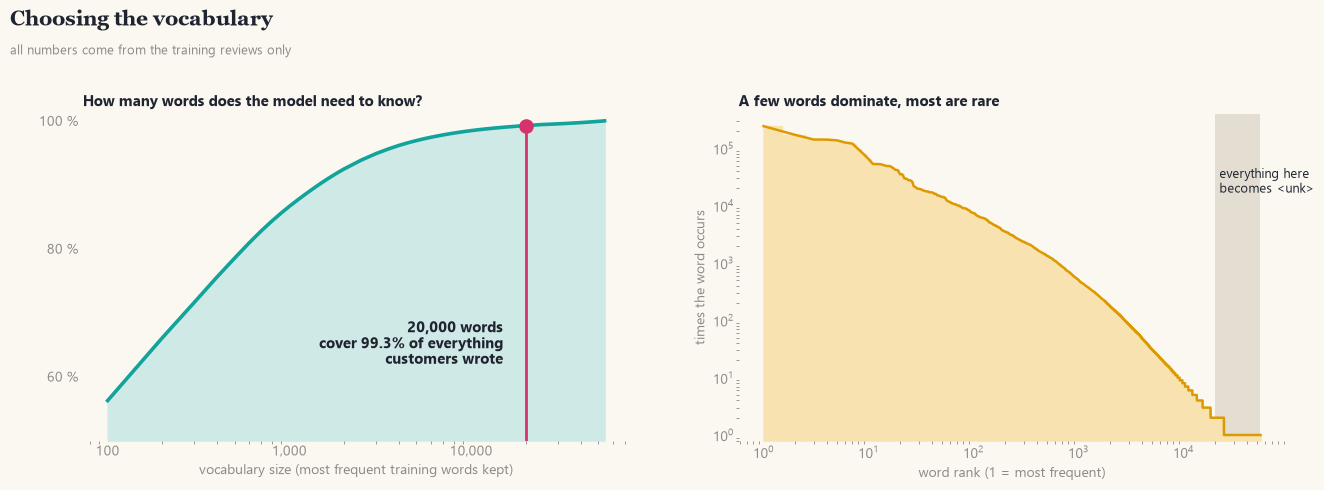

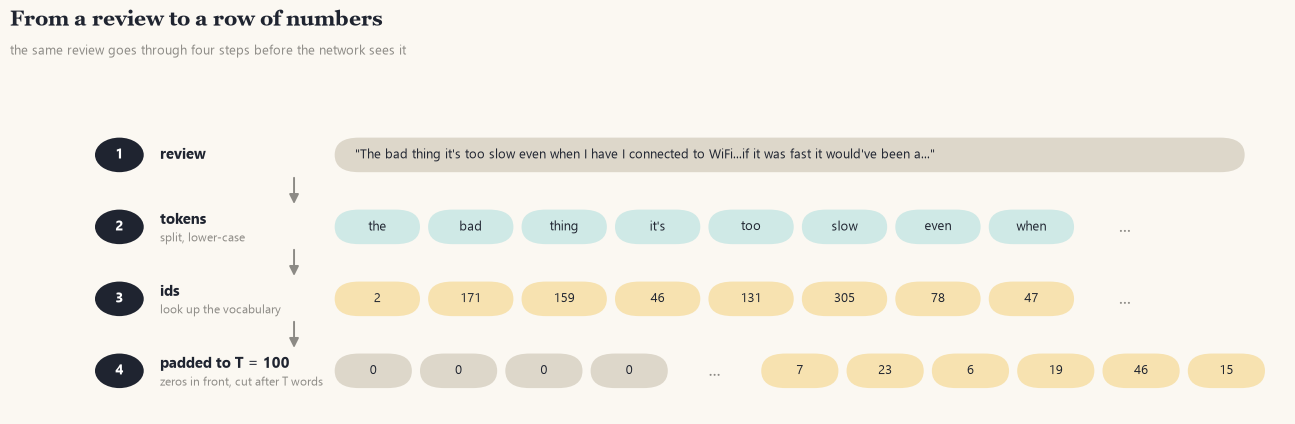

In [8]:
rank_counts = np.array([c for _, c in counts.most_common()])
coverage_curve = np.cumsum(rank_counts) / rank_counts.sum()
sizes = np.unique(np.r_[np.arange(100, 2000, 100), np.arange(2000, len(rank_counts), 500), len(rank_counts)])
cov = coverage_curve[VOCAB - 1]

fig = plt.figure(figsize=(13, 4.9)); gs = fig.add_gridspec(1, 2)
a = fig.add_subplot(gs[0])
a.fill_between(sizes, 100 * coverage_curve[sizes - 1], 50, color=C["teal_l"]); a.plot(sizes, 100 * coverage_curve[sizes - 1], color=C["rnn"], lw=2.6)
a.vlines(VOCAB, 50, 100 * cov, color=C["lstm"], lw=2); a.scatter([VOCAB], [100 * cov], s=90, color=C["lstm"], zorder=5)
a.text(VOCAB * 0.75, 62, f"{VOCAB:,} words\ncover {cov:.1%} of everything\ncustomers wrote", ha="right", fontsize=10.5, fontweight="bold")
a.set_xscale("log"); a.set_ylim(50, 101); a.set_xticks([100, 1000, 10000], ["100", "1,000", "10,000"]); a.set_yticks([60, 80, 100], ["60 %", "80 %", "100 %"])
a.set_xlabel("vocabulary size (most frequent training words kept)"); a.set_title("How many words does the model need to know?")
b = fig.add_subplot(gs[1]); r = np.arange(1, len(rank_counts) + 1)
b.axvspan(VOCAB, len(rank_counts), color=C["faint"], alpha=0.8, lw=0)
b.fill_between(r, rank_counts, 0.8, step="mid", color=C["amb_l"]); b.plot(r, rank_counts, color=C["pos"], lw=1.8)
b.set_xscale("log"); b.set_yscale("log"); b.set_ylim(0.8, rank_counts[0] * 1.6)
b.text(VOCAB * 1.1, rank_counts[40], "everything here\nbecomes <unk>", fontsize=9.5)
b.set_xlabel("word rank (1 = most frequent)"); b.set_ylabel("times the word occurs"); b.set_title("A few words dominate, most are rare")
headline(fig, "Choosing the vocabulary", "all numbers come from the training reviews only")
finish(fig, "EC_coverage")

# the four preparation steps on one real review
toks = tokenize(ex); ids_full = encode(ex); first_ids = [stoi.get(w, 1) for w in toks]
fig, ax = plt.subplots(figsize=(13, 4.6)); ax.set_xlim(0, 14.8); ax.set_ylim(-0.3, 4.9); ax.axis("off")
def chips(y, items, colors, x0=3.1, w=1.05, gap=0.1):
    for k, txt in enumerate(items):
        xc = x0 + k * (w + gap)
        if txt == "...": ax.text(xc + w / 2, y + 0.3, "...", ha="center", va="center", fontsize=14, color=C["mute"]); continue
        ax.add_patch(FancyBboxPatch((xc, y), w, 0.6, boxstyle="round,pad=0,rounding_size=0.3", fc=colors[k], ec="none")); ax.text(xc + w / 2, y + 0.3, txt, ha="center", va="center", fontsize=9)
rows = [(3.9, "review", ""), (2.65, "tokens", "split, lower-case"), (1.4, "ids", "look up the vocabulary"), (0.15, f"padded to T = {MAXLEN}", "zeros in front, cut after T words")]
for n_, (y, name, op) in enumerate(rows, 1):
    ax.add_patch(Circle((0.45, y + 0.3), 0.3, fc=C["ink"], ec="none")); ax.text(0.45, y + 0.3, str(n_), color="white", ha="center", va="center", fontweight="bold")
    ax.text(0.95, y + 0.3 + (0.12 if op else 0), name, va="center", fontsize=11, fontweight="bold")
    if op: ax.text(0.95, y + 0.3 - 0.2, op, va="center", fontsize=8.5, color=C["mute"])
ax.add_patch(FancyBboxPatch((3.1, 3.9), 11.2, 0.6, boxstyle="round,pad=0,rounding_size=0.3", fc=C["faint"], ec="none"))
ax.text(3.35, 4.2, '"' + ex[:100] + '..."', va="center", fontsize=9.5)
chips(2.65, toks[:8] + ["..."], [C["teal_l"]] * 8 + [C["paper"]]); chips(1.4, [str(i) for i in first_ids[:8]] + ["..."], [C["amb_l"]] * 8 + [C["paper"]])
pad = ["0", "0", "0", "0", "..."] + [str(i) for i in ids_full[-6:]]
chips(0.15, pad, [C["faint"]] * 4 + [C["paper"]] + [C["amb_l"]] * 6, w=0.95)
for y0, y1 in [(3.85, 3.3), (2.6, 2.05), (1.35, 0.8)]:
    ax.add_patch(FancyArrowPatch((2.6, y0), (2.6, y1), arrowstyle="-|>", mutation_scale=14, color=C["mute"], lw=1.4))
headline(fig, "From a review to a row of numbers", "the same review goes through four steps before the network sees it")
finish(fig, "EC_pipeline")

**Reading the vocabulary charts.** The left chart answers "how many words must the network know?". Coverage climbs steeply at first (the 1,000 most frequent words already cover 87 % of all word occurrences, the 5,000 most frequent 97 %), then flattens: going from 10,000 to 20,000 words adds less than one percentage point (98.5 % to 99.3 %) while doubling the size of the embedding table. The right chart shows why: sorted by frequency, the number of occurrences falls by five orders of magnitude, and the grey zone beyond rank 20,000 holds words that occur a handful of times. After encoding, only 0.73 % of the real tokens in the training matrix are `<unk>`, so the information lost by the cut is small.

**Shapes through the network.** Following the numbers through the model makes it concrete. A batch of 256 reviews is a table of word ids of shape `(256, 100)`. The embedding layer replaces every id by a learned vector of 64 numbers and gives `(256, 100, 64)`. Each of the five recurrent layers turns that sequence into another sequence of the same shape, one 64-number state per step. We keep only the last step of the top layer, `(256, 64)`, because by then the network has read the whole review, and a Dense layer with a sigmoid turns it into `(256, 1)`: the probability that the review is positive.

### How we measure

A single number cannot describe a classifier, so each run is scored in four ways. All of them start from the predictions on the test reviews, where a probability of at least 0.5 means "positive".

- **Accuracy**: the share of reviews classified correctly. Easy to understand, but misleading here because 70 % of the reviews are positive.
- **Precision and recall of the negative class**. *Recall* answers "of all truly negative reviews, how many did we find?", *precision* answers "of the reviews we called negative, how many really are?". A shop that wants to find unhappy customers cares about both: missing them is bad (low recall), and raising false alarms wastes the shop's time (low precision). Example: of 100 reviews, 30 are negative; a model finds 24 of them and wrongly flags 6 positive reviews; its recall is 24/30 = 0.8, its precision 24/30 = 0.8.
- **F1 score**: the harmonic mean of precision and recall, $F_1=2PR/(P+R)$, which is high only if both are high. The **F1 of the negative class** is the number that tells us how well the minority class is handled. The **macro-F1** is the average of the F1 scores of both classes, so the small negative class counts as much as the large positive one.
- **ROC-AUC**: the probability that a randomly chosen positive review gets a higher score than a randomly chosen negative one. 0.5 means guessing and 1 means perfect ranking. Unlike the others it does not depend on the 0.5 threshold, so it judges the quality of the scores themselves.

Every run goes through the helper `finalize`, which computes these numbers, stores the learning curves and writes everything to a JSON file so that the report can use it later. The helper `rnn_params` implements the parameter-count formula of the concepts notebook, and `EXPECTED` is what we expect Keras to count.

In [9]:
RUNS = {}

def metrics(y, p):
    yhat = (p >= 0.5).astype(int)
    return dict(accuracy=float(accuracy_score(y, yhat)), f1_macro=float(f1_score(y, yhat, average="macro")),
                f1_negative=float(f1_score(y, yhat, pos_label=0)), roc_auc=float(roc_auc_score(y, p)))

def finalize(run_id, p_test, history, params, sec_epoch, total_s):
    rec = dict(run_id=run_id, params=int(params), sec_per_epoch=round(sec_epoch, 2), train_seconds=round(total_s, 1),
               epochs=len(history["loss"]), best_epoch=int(np.argmin(history["val_loss"]) + 1),
               history=history, **metrics(yte, p_test))
    RUNS[run_id] = {**rec, "p_test": p_test}
    json.dump(rec, open(RES / f"{run_id}.json", "w"), indent=1)
    print(f"{run_id} finished: accuracy {rec['accuracy']:.4f}, macro-F1 {rec['f1_macro']:.4f}, AUC {rec['roc_auc']:.4f}. "
          f"It trained for {rec['epochs']} epochs (best epoch: {rec['best_epoch']}) at {sec_epoch:.0f} s per epoch.")
    return rec

def rnn_params(F, H, L, nb=1):  return F * H + H * H + nb * H + (L - 1) * (2 * H * H + nb * H)
def lstm_params(F, H, L, nb=1): return 4 * rnn_params(F, H, L, nb)
EXPECTED = {"RNN": VOCAB * EMB + rnn_params(EMB, H, LAYERS) + H + 1, "LSTM": VOCAB * EMB + lstm_params(EMB, H, LAYERS) + H + 1}
print("Parameter counts we expect (Keras counting, one bias vector per layer):", {k: f"{v:,}" for k, v in EXPECTED.items()})

Parameter counts we expect (Keras counting, one bias vector per layer): {'RNN': '1,321,345', 'LSTM': '1,445,185'}


## 4. Baselines

A score means little without something to compare it with. Two baselines frame the results.

**Majority class.** Always answer "positive". It uses no information at all, so its accuracy (the share of positive reviews, 0.70) is the floor: a model that does not beat it has learned nothing. Its F1 for the negative class is exactly 0, which is why we track that number.

**TF-IDF + logistic regression.** This is a strong classical text classifier and the fair opponent for a recurrent network, because it ignores word order completely. Each review is turned into a long vector with one entry per word or per word pair (a *bigram* such as "not good"), and each entry is the **TF-IDF** weight of that word: how often the word occurs in this review (the term frequency, damped with a logarithm so that saying a word ten times does not count ten times) multiplied by how rare the word is across all reviews (the inverse document frequency). A word that occurs in nearly every review ("the") gets a weight close to zero, while a word that is frequent in this review but rare overall ("defective") gets a large one. A logistic regression then learns one weight per entry and adds up the weights of the entries present: a weighted vote of the words. It trains in seconds, and because we saw in §2 that many words are clear signals we should expect it to be hard to beat. If a recurrent network cannot beat it, the network's ability to read word order is not paying off.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
BASE = {}
BASE["majority"] = metrics(yte, np.ones_like(yte) * 0.99)
t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=200_000, sublinear_tf=True)
lr = LogisticRegression(max_iter=2000, C=4).fit(tfidf.fit_transform(texts[i_tr]), ytr)
p_lr = lr.predict_proba(tfidf.transform(texts[i_te]))[:, 1]
BASE["tfidf_logreg"] = metrics(yte, p_lr)
print(f"Training the TF-IDF + logistic regression baseline took {time.time() - t0:.0f} seconds. Scores of both baselines on the test reviews:")
display(pd.DataFrame(BASE).T.round(4))

Training the TF-IDF + logistic regression baseline took 9 seconds. Scores of both baselines on the test reviews:


,accuracy,f1_macro,f1_negative,roc_auc
majority,0.7006,0.4120,0.0000,0.5000
tfidf_logreg,0.9414,0.9298,0.9011,0.9825


**Reading the baselines.** The majority classifier reaches 0.7006 accuracy and an F1 of 0 on the negative class, as predicted. TF-IDF + logistic regression reaches 0.9414 accuracy, 0.9011 F1 on the negative class and 0.9825 ROC-AUC after only 9 seconds of training. That is a high bar, and it already tells us something about the task: the sentiment of these reviews is carried largely by individual words, so a model that merely counts words does very well. The recurrent networks have to be measured against this number, not against 0.70.

## 5. Keras — runs `EC-TF-RNN`, `EC-TF-LSTM`

In Keras a network is a list of layers. For this task the list is:

- **Embedding**(20000, 64). A word id is only a label: id 171 is not "bigger" or "more negative" than id 170. The embedding layer is a lookup table with 20,000 rows of 64 numbers, and it replaces each id by its row. The rows start random and are trained together with the rest of the network, so words that are used in similar ways end up with similar vectors. This hands the recurrent layers meaningful numbers instead of arbitrary labels, and it is where most of the network's parameters live.
- four recurrent layers with `return_sequences=True`. A layer normally returns only its final state; with this option it returns the state at every step, a whole sequence, which is what the next layer needs as input.
- a fifth recurrent layer with `return_sequences=False`, which returns only its last state $h^{(5)}_T$, the summary of the whole review.
- **Dense**(1, sigmoid): one weighted sum of the 64 numbers, squashed into a probability.

`SimpleRNN` computes $h_t=\tanh(x_tW+h_{t-1}U+b)$ and `LSTM` adds the gates (both are derived in the concepts notebook). We keep Keras's defaults: Glorot-uniform input weights, orthogonal recurrent weights, zero biases and, for the LSTM, a forget-gate bias of 1, because the PyTorch version in §6 will be set to start from the same values. `model.fit` then runs the whole training loop: batches, loss, gradients, Adam updates, validation and early stopping.

In [11]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)
print(f"Using TensorFlow {tf.__version__}; GPUs found: {len(tf.config.list_physical_devices('GPU'))} (0 means everything runs on the CPU).")

def build_keras(kind):
    cell = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM}[kind]
    stack = [layers.Input((MAXLEN,), dtype="int32"), layers.Embedding(VOCAB, EMB)]
    stack += [cell(H, return_sequences=(l < LAYERS - 1)) for l in range(LAYERS)]
    stack += [layers.Dense(1, activation="sigmoid")]
    m = keras.Sequential(stack, name=f"keras_{kind}")
    m.compile(optimizer=keras.optimizers.Adam(LR, clipnorm=CLIP), loss="binary_crossentropy", metrics=["accuracy"])
    return m

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self.t = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self.t)

def run_keras(kind):
    tf.keras.utils.set_random_seed(SEED)
    m = build_keras(kind)
    assert m.count_params() == EXPECTED[kind], (m.count_params(), EXPECTED[kind])
    timer = EpochTimer(); t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=BATCH, verbose=2,
              callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True), timer])
    p = m.predict(Xte, batch_size=1024, verbose=0)[:, 0]
    hist = {"loss": h.history["loss"], "val_loss": h.history["val_loss"], "acc": h.history["accuracy"], "val_acc": h.history["val_accuracy"]}
    return finalize(f"EC-TF-{kind}", p, hist, m.count_params(), float(np.median(timer.times[1:] or timer.times)), time.time() - t0)

build_keras("RNN").summary()

Using TensorFlow 2.22.0-rc0; GPUs found: 0 (0 means everything runs on the CPU).


Model: "keras_RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 100, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 100, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 100, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 100, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,321,345 (5.04 MB)

 Trainable params: 1,321,345 (5.04 MB)

 Non-trainable params: 0 (0.00 B)

**Checking the parameter count.** Before training we verify that the model has exactly the number of parameters that our formula from the concepts notebook predicts, a cheap guard against building the wrong network. The embedding holds $20{,}000\cdot64=1{,}280{,}000$ numbers. The first recurrent layer maps 64 inputs to 64 units, which costs $64\cdot64$ input weights $+\,64\cdot64$ recurrent weights $+\,64$ biases $=8{,}256$ numbers; layers 2 to 5 have the same size, and the output layer has $64+1=65$. Almost everything sits in the embedding table: the five recurrent layers hold only 41,280 parameters in the RNN and 165,120 in the LSTM (four times as many, one copy per gate). This is worth remembering when we compare the models later: **the LSTM makes the whole network only about 9 % larger**, because the embedding dominates both.

In [12]:
run_keras("RNN");

Epoch 1/10


406/406 - 55s - 136ms/step - accuracy: 0.8742 - loss: 0.3002 - val_accuracy: 0.9115 - val_loss: 0.2165


Epoch 2/10


406/406 - 42s - 103ms/step - accuracy: 0.9288 - loss: 0.1911 - val_accuracy: 0.9184 - val_loss: 0.2139


Epoch 3/10


406/406 - 43s - 107ms/step - accuracy: 0.9408 - loss: 0.1632 - val_accuracy: 0.9074 - val_loss: 0.2376


Epoch 4/10


406/406 - 43s - 106ms/step - accuracy: 0.9468 - loss: 0.1483 - val_accuracy: 0.9116 - val_loss: 0.2388


EC-TF-RNN finished: accuracy 0.9225, macro-F1 0.9084, AUC 0.9707. It trained for 4 epochs (best epoch: 2) at 43 s per epoch.


In [13]:
run_keras("LSTM");

Epoch 1/10


406/406 - 194s - 478ms/step - accuracy: 0.8823 - loss: 0.2809 - val_accuracy: 0.9182 - val_loss: 0.2061


Epoch 2/10


406/406 - 199s - 490ms/step - accuracy: 0.9359 - loss: 0.1705 - val_accuracy: 0.9258 - val_loss: 0.1936


Epoch 3/10


406/406 - 198s - 489ms/step - accuracy: 0.9468 - loss: 0.1451 - val_accuracy: 0.9268 - val_loss: 0.2118


Epoch 4/10


406/406 - 191s - 471ms/step - accuracy: 0.9552 - loss: 0.1255 - val_accuracy: 0.9140 - val_loss: 0.2431


EC-TF-LSTM finished: accuracy 0.9301, macro-F1 0.9161, AUC 0.9745. It trained for 4 epochs (best epoch: 2) at 198 s per epoch.


**Reading the Keras runs.** Both networks reach their lowest validation loss early: after 2 epochs, with 0.214 (RNN) and 0.194 (LSTM). After that the validation loss rises (to 0.239 and 0.243 at epoch 4) while the training loss keeps falling (the RNN's from 0.30 to 0.15). This is overfitting in action: from epoch 3 on the networks fit the particular training reviews better and unseen reviews worse. The large embedding table, 1.28 million of the 1.32 million parameters, can memorise a great deal. Early stopping notices after two epochs without improvement and restores the weights of the best epoch, so the test scores come from epoch 2.

The cost of the LSTM is already visible here: about 198 seconds per epoch against 43 for the RNN, about 4.6 times as long, because every step computes four gates instead of one tanh.

## 6. PyTorch — runs `EC-PT-RNN`, `EC-PT-LSTM`

PyTorch describes the same network as a Python class. `nn.Embedding` looks up the word vectors, `nn.RNN(64, 64, num_layers=5, batch_first=True)` (or `nn.LSTM`) is the whole stack of five recurrent layers in a single call, the composition $f^{(5)}\circ\dots\circ f^{(1)}$ of the concepts notebook, `out[:, -1]` picks the last step of the top layer, and `nn.Linear(64, 1)` produces one score. Unlike Keras, the training loop is written by hand, and writing it out shows what `model.fit` was doing for us: take a batch, **forward** pass, compute the **loss**, clear the old gradients (`zero_grad`), **backward** pass to compute new gradients, **clip** them, and let the optimizer **step**. After each epoch we evaluate on the validation reviews and apply the same early-stopping rule as before.

Two details make the comparison with Keras fair. First, PyTorch's default starting weights differ from Keras's, and a different starting point can change the result by itself. So we overwrite them with Keras's recipe: Glorot-uniform input weights, orthogonal recurrent weights, zero biases, an LSTM forget bias of 1 (the concepts notebook shows why this matters) and embedding values uniform in ±0.05. Second, PyTorch keeps **two** bias vectors per layer (`bias_ih` and `bias_hh`) where Keras keeps one. Only their sum matters, so the function computed is identical, but PyTorch's models carry $5\cdot64=320$ (RNN) or $5\cdot256=1{,}280$ (LSTM) extra numbers, all starting at zero.

In [14]:
import torch, torch.nn as nn
torch.manual_seed(SEED)
DEV = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Using PyTorch {torch.__version__} on the {DEV.type.upper()}.")

class TorchSentiment(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.emb = nn.Embedding(VOCAB, EMB)
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM}[kind](EMB, H, num_layers=LAYERS, batch_first=True)
        self.head = nn.Linear(H, 1)
        nn.init.uniform_(self.emb.weight, -0.05, 0.05)
        for name, p in self.rnn.named_parameters():                # Keras-style initialisation
            if name.startswith("weight_ih"):
                for blk in p.data.chunk(4 if kind == "LSTM" else 1): nn.init.xavier_uniform_(blk)
            elif name.startswith("weight_hh"):
                for blk in p.data.chunk(4 if kind == "LSTM" else 1): nn.init.orthogonal_(blk)
            else:
                nn.init.zeros_(p)
                if kind == "LSTM" and name.startswith("bias_ih"): p.data[H:2 * H] = 1.0   # forget gate
        nn.init.xavier_uniform_(self.head.weight); nn.init.zeros_(self.head.bias)
    def forward(self, x):                      # x: (B, T) word ids
        out, _ = self.rnn(self.emb(x))         # out: (B, T, H), states of the top layer
        return self.head(out[:, -1]).squeeze(1)   # logit from h^(5)_T

def predict_torch(model, X, bs=1024):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(torch.sigmoid(model(torch.from_numpy(X[i:i + bs]).long().to(DEV))).cpu().numpy())
    return np.concatenate(out)

def run_torch(kind):
    torch.manual_seed(SEED)
    m = TorchSentiment(kind).to(DEV)
    n = sum(p.numel() for p in m.parameters()); extra = LAYERS * H * (4 if kind == "LSTM" else 1)
    assert n == EXPECTED[kind] + extra, (n, EXPECTED[kind], extra)
    opt = torch.optim.Adam(m.parameters(), lr=LR, eps=1e-7); lossf = nn.BCEWithLogitsLoss()
    Xt, yt = torch.from_numpy(Xtr).long(), torch.from_numpy(ytr)
    Xv, yv = torch.from_numpy(Xva).long().to(DEV), torch.from_numpy(yva).to(DEV)
    hist = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}; times = []; best, best_state, wait = np.inf, None, 0
    g = torch.Generator().manual_seed(SEED); t0 = time.time()
    for ep in range(EPOCHS):
        m.train(); te = time.time(); tot, correct = 0.0, 0
        for b in torch.randperm(len(Xt), generator=g).split(BATCH):
            xb, yb = Xt[b].to(DEV), yt[b].to(DEV)
            logit = m(xb); loss = lossf(logit, yb)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), CLIP); opt.step()
            tot += loss.item() * len(b); correct += ((logit > 0).float() == yb).sum().item()
        m.eval()
        with torch.no_grad():
            vl, vc = 0.0, 0
            for i in range(0, len(Xv), 1024):
                lo = m(Xv[i:i + 1024]); vl += lossf(lo, yv[i:i + 1024]).item() * len(lo); vc += ((lo > 0).float() == yv[i:i + 1024]).sum().item()
        times.append(time.time() - te)
        hist["loss"].append(tot / len(Xt)); hist["val_loss"].append(vl / len(Xv)); hist["acc"].append(correct / len(Xt)); hist["val_acc"].append(vc / len(Xv))
        print(f"epoch {ep + 1}: training loss {hist['loss'][-1]:.4f}, validation loss {hist['val_loss'][-1]:.4f}, validation accuracy {hist['val_acc'][-1]:.4f} ({times[-1]:.0f} s)")
        if hist["val_loss"][-1] < best - 1e-4:
            best, wait = hist["val_loss"][-1], 0; best_state = {k: v.detach().clone() for k, v in m.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE: break
    m.load_state_dict(best_state)
    return finalize(f"EC-PT-{kind}", predict_torch(m, Xte), hist, n, float(np.median(times[1:] or times)), time.time() - t0)

print(TorchSentiment("LSTM"))

Using PyTorch 2.14.1+cpu on the CPU.
TorchSentiment(
  (emb): Embedding(20000, 64)
  (rnn): LSTM(64, 64, num_layers=5, batch_first=True)
  (head): Linear(in_features=64, out_features=1, bias=True)
)


In [15]:
run_torch("RNN");

epoch 1: training loss 0.3216, validation loss 0.2501, validation accuracy 0.9126 (40 s)


epoch 2: training loss 0.2172, validation loss 0.2197, validation accuracy 0.9143 (39 s)


epoch 3: training loss 0.1905, validation loss 0.2372, validation accuracy 0.9120 (42 s)


epoch 4: training loss 0.1753, validation loss 0.2286, validation accuracy 0.9159 (48 s)


EC-PT-RNN finished: accuracy 0.9183, macro-F1 0.8999, AUC 0.9676. It trained for 4 epochs (best epoch: 2) at 42 s per epoch.


In [16]:
run_torch("LSTM");

epoch 1: training loss 0.2979, validation loss 0.2082, validation accuracy 0.9204 (98 s)


epoch 2: training loss 0.1684, validation loss 0.2257, validation accuracy 0.9112 (94 s)


epoch 3: training loss 0.1332, validation loss 0.2026, validation accuracy 0.9287 (95 s)


epoch 4: training loss 0.1091, validation loss 0.2029, validation accuracy 0.9264 (90 s)


epoch 5: training loss 0.0899, validation loss 0.2096, validation accuracy 0.9266 (91 s)


EC-PT-LSTM finished: accuracy 0.9311, macro-F1 0.9176, AUC 0.9760. It trained for 5 epochs (best epoch: 3) at 93 s per epoch.


**Reading the PyTorch runs.** The picture is the same as in Keras, with more noise. The RNN's best epoch is 2 (validation loss 0.220) and then the validation loss wobbles upward; the LSTM keeps improving until epoch 3 (validation loss 0.203) and stops at epoch 5 after two epochs without improvement. Its validation loss is bumpy (0.208, 0.226, 0.203, 0.203, 0.210), which shows that a single validation number is a noisy guide: which epoch is "best" depends partly on chance. The LSTM again takes longer per epoch (93 seconds against 42), about 2.2 times as long, a smaller ratio than in Keras, so how much slower an LSTM is depends on how well each library optimises it on a CPU.

## 7. Comparison

All four networks and both baselines have now been evaluated on the **same 22,219 test reviews**, which no model saw during training or early stopping. We look at the results from several angles: the table of scores, a picture of the same scores, the learning curves (how training went), the errors each model makes, and how accuracy changes with review length, which is the question this assignment is really about.

In [17]:
rows = [{"run": k, **{m: v[m] for m in ["accuracy", "f1_macro", "f1_negative", "roc_auc", "params", "sec_per_epoch", "epochs", "best_epoch"]}} for k, v in RUNS.items()]
rows += [{"run": f"baseline: {k}", **v} for k, v in BASE.items()]
table = pd.DataFrame(rows).set_index("run")
table.to_csv(RES / "EC_comparison.csv")
display(table.round(4))

,accuracy,f1_macro,f1_negative,roc_auc,params,sec_per_epoch,epochs,best_epoch
run,,,,,,,,
EC-TF-RNN,0.9225,0.9084,0.8726,0.9707,1321345.0,43.15,4.0,2.0
EC-TF-LSTM,0.9301,0.9161,0.8817,0.9745,1445185.0,198.45,4.0,2.0
EC-PT-RNN,0.9183,0.8999,0.8570,0.9676,1321665.0,42.11,4.0,2.0
EC-PT-LSTM,0.9311,0.9176,0.8844,0.9760,1446465.0,92.56,5.0,3.0
baseline: majority,0.7006,0.4120,0.0000,0.5000,NaN,NaN,NaN,NaN
baseline: tfidf_logreg,0.9414,0.9298,0.9011,0.9825,NaN,NaN,NaN,NaN


**Reading the table.** Looking at the rows, we see that all four recurrent networks land between 0.918 and 0.931 accuracy, far above the majority baseline (0.70) but, to our surprise, **below the TF-IDF baseline (0.941)**. Among the networks the pattern is the same in both frameworks: the LSTM beats the RNN, by 0.8 points of accuracy in Keras (0.9301 against 0.9225) and 1.3 points in PyTorch (0.9311 against 0.9183), and the gap grows for the negative class, where the LSTM's F1 is higher by 0.9 points (Keras) and 2.7 points (PyTorch). The ROC-AUC tells the same story (0.9745 against 0.9707, and 0.9760 against 0.9676). The two frameworks agree on accuracy within half a point for the same architecture, so the difference between RNN and LSTM is larger than the difference between libraries: it is a property of the models, not of the software.

The price of the LSTM is time (198 against 43 seconds per epoch in Keras, 93 against 42 in PyTorch, i.e. 2.2 to 4.6 times as long) for a network that is only 9 % larger overall.

### Scoreboard

The same numbers as the table, drawn as one line per model across the three metrics. Each metric axis is stretched so that the best model touches the top and the worst the bottom, and the real values are printed at both ends. The majority-class baseline (accuracy 0.70, negative-class F1 0.00, AUC 0.50) is left out because it would squash all other lines together.

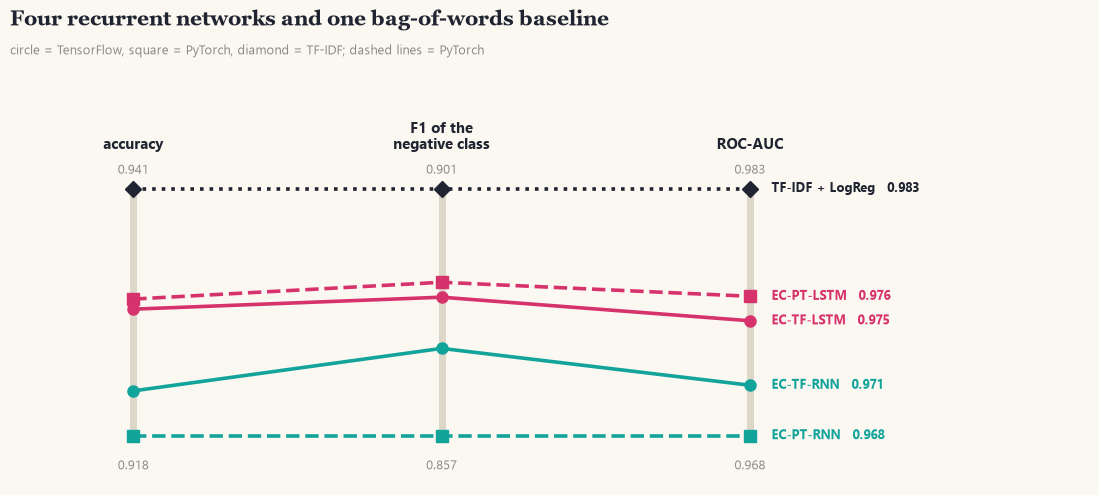

In [18]:
order = list(RUNS) + ["tfidf_logreg"]
values = {**{k: RUNS[k] for k in RUNS}, "tfidf_logreg": BASE["tfidf_logreg"]}
metrics = [("accuracy", "accuracy"), ("f1_negative", "F1 of the\nnegative class"), ("roc_auc", "ROC-AUC")]
M = np.array([[values[k][m] for m, _ in metrics] for k in order]); lo_, hi_ = M.min(0), M.max(0); Z = (M - lo_) / (hi_ - lo_ + 1e-12)
fig, ax = plt.subplots(figsize=(11, 5.4))
for j, (_, title) in enumerate(metrics):
    ax.plot([j, j], [0, 1], color=C["faint"], lw=5, solid_capstyle="round", zorder=0)
    ax.text(j, 1.16, title, ha="center", fontweight="bold", fontsize=10.5)
    ax.text(j, 1.06, f"{hi_[j]:.3f}", ha="center", fontsize=9, color=C["mute"]); ax.text(j, -0.1, f"{lo_[j]:.3f}", ha="center", va="top", fontsize=9, color=C["mute"])
for i, k in enumerate(order):
    col, ls = (style(k)["color"], style(k)["ls"]) if k in RUNS else (C["ink"], ":")
    ax.plot(range(3), Z[i], color=col, ls=ls, lw=2.6, marker=mk(k) if k in RUNS else "D", ms=8, zorder=3)
    ax.text(2.07, Z[i, 2], f"{k if k in RUNS else 'TF-IDF + LogReg'}   {M[i, 2]:.3f}", va="center", color=col, fontsize=9.5, fontweight="bold")
ax.set_xlim(-0.2, 3.1); ax.set_ylim(-0.2, 1.3); ax.axis("off")
headline(fig, "Four recurrent networks and one bag-of-words baseline", "circle = TensorFlow, square = PyTorch, diamond = TF-IDF; dashed lines = PyTorch")
finish(fig, "EC_scores")

**Reading the scoreboard.** The two LSTM lines run together in the upper part and the two RNN lines lower down, on every axis: the ranking LSTM above RNN does not depend on which metric we pick. The TF-IDF line, however, lies above all four networks on all three axes. In other words, a model that does not look at word order at all is a little better than every recurrent network we trained, which is the main surprise of this experiment. We come back to why in the conclusion.

### Learning curves

Each cluster of dumbbells is one run, with one dumbbell per epoch: the hollow dot is the loss on the training reviews, the filled dot the loss on the validation reviews, and the grey bar between them is the gap. The black ring marks the epoch that early stopping kept. The table on the right shows the validation accuracy per epoch. What to look for: the gap that opens up when the network starts to memorise its training data, and how many epochs the best result needs.

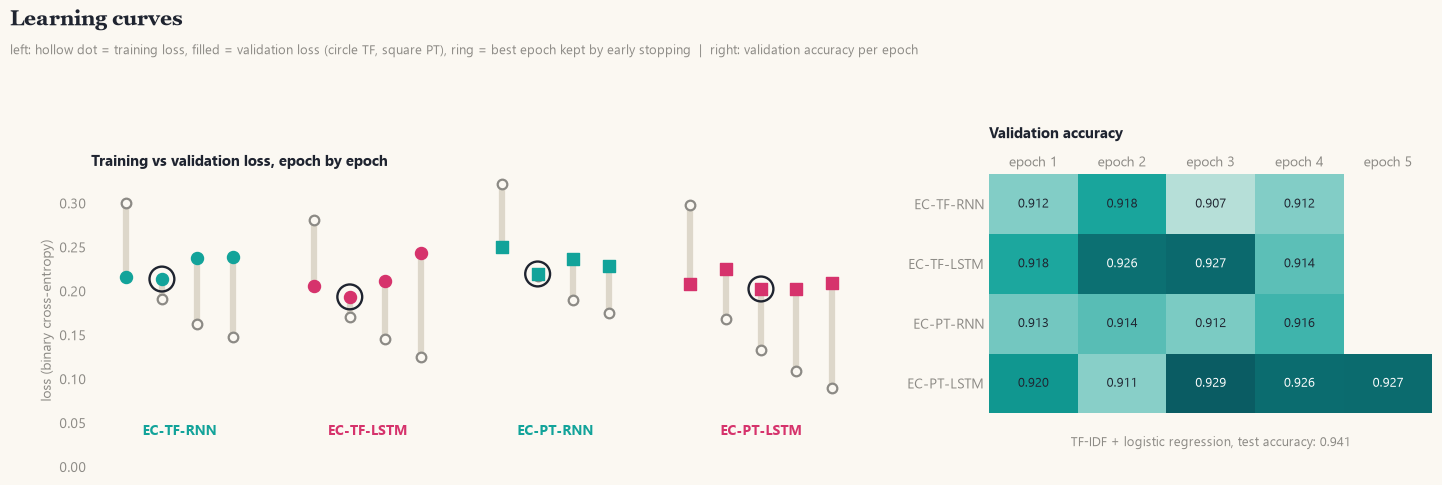

In [19]:
fig = plt.figure(figsize=(14.5, 5.2)); gs = fig.add_gridspec(1, 2, width_ratios=[1.75, 1])
a = fig.add_subplot(gs[0]); x0 = 0.0
ylo = min(min(v["history"]["loss"]) for v in RUNS.values()) - 0.03
for k, v in RUNS.items():
    h = v["history"]; n = len(h["loss"]); col = style(k)["color"]
    for e in range(n):
        x = x0 + e
        a.plot([x, x], [h["loss"][e], h["val_loss"][e]], color=C["faint"], lw=4.5, solid_capstyle="round", zorder=1)
        a.scatter(x, h["loss"][e], s=48, facecolor=C["paper"], edgecolor=C["mute"], lw=1.6, zorder=3)
        a.scatter(x, h["val_loss"][e], s=75, color=col, marker=mk(k), zorder=4)
    b = v["best_epoch"] - 1
    a.scatter(x0 + b, h["val_loss"][b], s=320, facecolor="none", edgecolor=C["ink"], lw=1.7, zorder=5)
    a.text(x0 + (n - 1) / 2, ylo - 0.012, k, ha="center", va="top", color=col, fontweight="bold")
    x0 += n + 1.3
a.set_xticks([]); a.set_ylim(ylo - 0.06, None); a.set_ylabel("loss (binary cross-entropy)"); a.set_title("Training vs validation loss, epoch by epoch")
maxe = max(len(v["history"]["val_acc"]) for v in RUNS.values()); T_ = np.full((len(RUNS), maxe), np.nan)
for i, v in enumerate(RUNS.values()): T_[i, :len(v["history"]["val_acc"])] = v["history"]["val_acc"]
tb = fig.add_subplot(gs[1]); tb.imshow(T_, cmap=SEQ, vmin=np.nanmin(T_) - 0.008, vmax=np.nanmax(T_), aspect="auto")
for (i, j), val in np.ndenumerate(T_):
    if not np.isnan(val): tb.text(j, i, f"{val:.3f}", ha="center", va="center", fontsize=9.5, color="white" if val > np.nanmin(T_) + 0.65 * (np.nanmax(T_) - np.nanmin(T_)) else C["ink"])
tb.set_yticks(range(len(RUNS)), list(RUNS)); tb.set_xticks(range(maxe), [f"epoch {e + 1}" for e in range(maxe)]); tb.xaxis.tick_top()
tb.set_ylim(len(RUNS) + 0.4, -0.5); tb.text((maxe - 1) / 2, len(RUNS) + 0.05, f"TF-IDF + logistic regression, test accuracy: {BASE['tfidf_logreg']['accuracy']:.3f}", ha="center", fontsize=9, color=C["mute"])
tb.set_title("Validation accuracy", pad=26)
headline(fig, "Learning curves", "left: hollow dot = training loss, filled = validation loss (circle TF, square PT), ring = best epoch kept by early stopping  |  right: validation accuracy per epoch")
finish(fig, "EC_curves", top_in=1.7)

**Reading the learning curves.** In the first epoch the filled dot sits *below* the hollow one: the training loss is an average over the epoch while the network was still changing, whereas the validation loss is measured after the epoch with the improved weights. From epoch 2 or 3 on the order flips, the training loss keeps dropping and the validation loss stops improving or rises, so the grey bar grows: the networks are learning the training reviews by heart. The LSTM runs fall furthest (the PyTorch LSTM's training loss reaches 0.09 while its validation loss stays above 0.20), which is expected from a model with four times as many recurrent parameters. All four runs keep an epoch between 2 and 3, so extra training would not have helped; more data, a smaller embedding or regularisation such as dropout would be the remedies, which we did not apply to keep the architectures identical to the assignment.

The validation accuracy in the table moves by up to a point from one epoch to the next without a clear trend (the Keras RNN: 0.912, 0.918, 0.907, 0.912), which warns us that differences of a few tenths of a point between two models are within the noise of a single run.

### Where the errors go, and how the models rank reviews

The top lollipops show, for each run, which share of the truly negative reviews is wrongly called positive and which share of the truly positive reviews is wrongly called negative. The bottom row shows the ROC curve of every run, zoomed into the corner where the interesting part is: the curve plots the share of positive reviews found (true positive rate) against the share of negative reviews wrongly accepted (false positive rate) as the decision threshold moves, so a curve that hugs the top-left corner ranks reviews better, and the shaded area is the AUC. The dotted line is the TF-IDF baseline in the same panel.

EC-TF-RNN: 757 of 6,653 negative reviews called positive (11.4 %), 965 of 15,566 positive reviews called negative (6.2 %)
EC-TF-LSTM: 869 of 6,653 negative reviews called positive (13.1 %), 683 of 15,566 positive reviews called negative (4.4 %)
EC-PT-RNN: 1,213 of 6,653 negative reviews called positive (18.2 %), 602 of 15,566 positive reviews called negative (3.9 %)
EC-PT-LSTM: 798 of 6,653 negative reviews called positive (12.0 %), 733 of 15,566 positive reviews called negative (4.7 %)


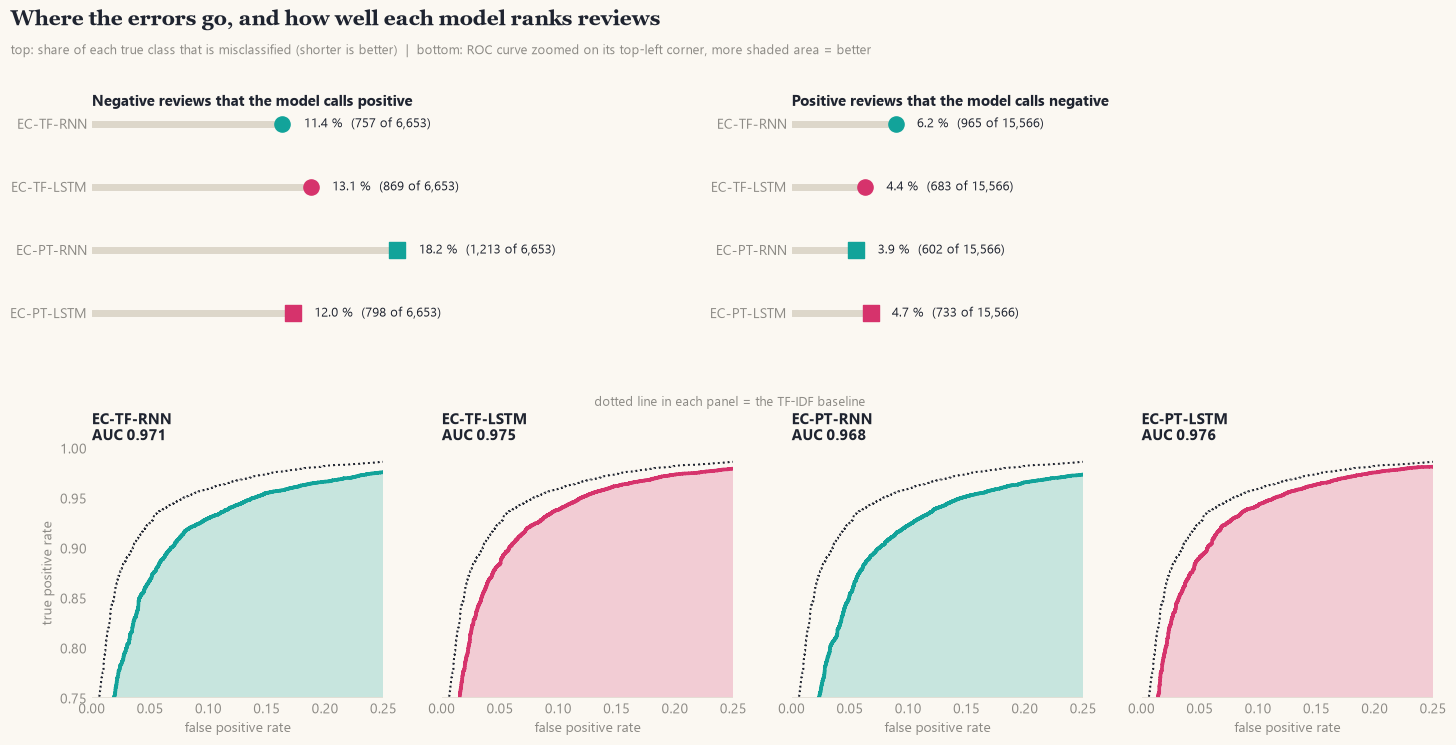

In [20]:
fig = plt.figure(figsize=(14.5, 7.8)); gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.2], hspace=0.55)
errs = {}
for k, v in RUNS.items():
    cm = confusion_matrix(yte, (v["p_test"] >= 0.5).astype(int)); errs[k] = (cm[0, 1], cm[0].sum(), cm[1, 0], cm[1].sum())
for k in RUNS:
    print(f"{k}: {errs[k][0]:,} of {errs[k][1]:,} negative reviews called positive ({100 * errs[k][0] / errs[k][1]:.1f} %), "
          f"{errs[k][2]:,} of {errs[k][3]:,} positive reviews called negative ({100 * errs[k][2] / errs[k][3]:.1f} %)")
rmax = max(100 * errs[k][i] / errs[k][i + 1] for k in RUNS for i in (0, 2))
for col, (title, idx) in enumerate([("Negative reviews that the model calls positive", 0), ("Positive reviews that the model calls negative", 2)]):
    a = fig.add_subplot(gs[0, 2 * col: 2 * col + 2]); keys = list(RUNS)[::-1]
    for y_, k in enumerate(keys):
        e, tot = errs[k][idx], errs[k][idx + 1]; rate = 100 * e / tot
        a.plot([0, rate], [y_, y_], color=C["faint"], lw=5, solid_capstyle="round", zorder=1); a.scatter(rate, y_, s=120, color=style(k)["color"], marker=mk(k), zorder=3)
        a.text(rate + 0.07 * rmax, y_, f"{rate:.1f} %  ({e:,} of {tot:,})", va="center", fontsize=9.5)
    a.set_yticks(range(len(keys)), keys); a.set_xlim(0, rmax * 2.1); a.set_xticks([]); a.set_title(title)
f2, t2, _ = roc_curve(yte, p_lr)
for j, (k, v) in enumerate(RUNS.items()):
    a = fig.add_subplot(gs[1, j]); fpr, tpr, _ = roc_curve(yte, v["p_test"]); col = style(k)["color"]
    a.fill_between(fpr, tpr, 0.75, color=col, alpha=0.22, lw=0); a.plot(fpr, tpr, color=col, lw=2.6); a.plot(f2, t2, color=C["ink"], lw=1.4, ls=":")
    a.axhline(0.75, color=C["rule"], lw=2); a.set_xlim(0, 0.25); a.set_ylim(0.75, 1.0)
    a.set_title(f"{k}\nAUC {v['roc_auc']:.3f}", fontsize=10.5); a.set_xlabel("false positive rate")
    if j == 0: a.set_ylabel("true positive rate")
    else: a.set_yticks([])
fig.text(0.5, 0.485, "dotted line in each panel = the TF-IDF baseline", ha="center", fontsize=9, color=C["mute"])
headline(fig, "Where the errors go, and how well each model ranks reviews", "top: share of each true class that is misclassified (shorter is better)  |  bottom: ROC curve zoomed on its top-left corner, more shaded area = better")
finish(fig, "EC_confusion_roc")

**Reading the error charts.** The counts are printed above the charts and drawn as the lollipops. All four runs mislabel a larger share of the *negative* reviews than of the positive ones, which is the price of being the minority class: the Keras RNN lets 757 of the 6,653 negative test reviews pass as positive (11.4 %), the Keras LSTM 869 (13.1 %), the PyTorch LSTM 798 (12.0 %) and the PyTorch RNN as many as 1,213 (18.2 %). Of the 15,566 positive reviews only 3.9 to 6.2 % are called negative. A shop that wants to catch unhappy customers therefore misses between one in nine and one in five of them with any of these models.

The two architectures trade the two kinds of mistake differently. In Keras the LSTM catches fewer complaints than the RNN (13.1 % missed against 11.4 %) but raises far fewer false alarms (4.4 % of the positive reviews against 6.2 %), so its precision on the negative class is higher at a similar recall. In PyTorch it is the other way round for the complaints: the LSTM misses 12.0 % against 18.2 % for the RNN, at the price of slightly more false alarms (4.7 % against 3.9 %). The PyTorch RNN is the weakest run on negative reviews, which is exactly what its low negative-class F1 (0.857) said. Which of these profiles is better depends on the shop, so the F1 of the negative class, which weighs both, is the fair summary.

In the ROC panels the order of the AUC values is visible as the order of the curves. Among the networks, the LSTM curves lie closer to the top-left corner than the RNN curves (AUC 0.9745 and 0.9760 against 0.9707 and 0.9676), and the dotted TF-IDF curve (AUC 0.9825) is the one that lies highest overall. Where exactly the curves cross, and whether a network beats the baseline at very low false-positive rates, is a detail that a single run cannot settle, so we do not draw conclusions from it.

### Does the LSTM read long reviews better?

This is the central question of the assignment. If the RNN loses information over many steps (the vanishing gradient of the concepts notebook), its accuracy should fall faster on long reviews than the LSTM's. The upper table gives the test accuracy in each length bucket, the lower table the gain of the LSTM over the RNN in points (magenta where the LSTM is better, teal where the RNN is better). Remember the pre-padding: in a 10-word review the first 90 steps are padding and the 10 real words come last, so a short review needs almost no memory at all.

,EC-TF-RNN,EC-TF-LSTM,EC-PT-RNN,EC-PT-LSTM,reviews
1-10,0.950,0.952,0.945,0.954,5955
11-20,0.929,0.936,0.920,0.938,3697
21-40,0.926,0.937,0.926,0.936,5546
41-70,0.914,0.925,0.907,0.923,3070
71-100,0.911,0.919,0.907,0.918,1458
>100 (cut),0.855,0.868,0.855,0.874,2493


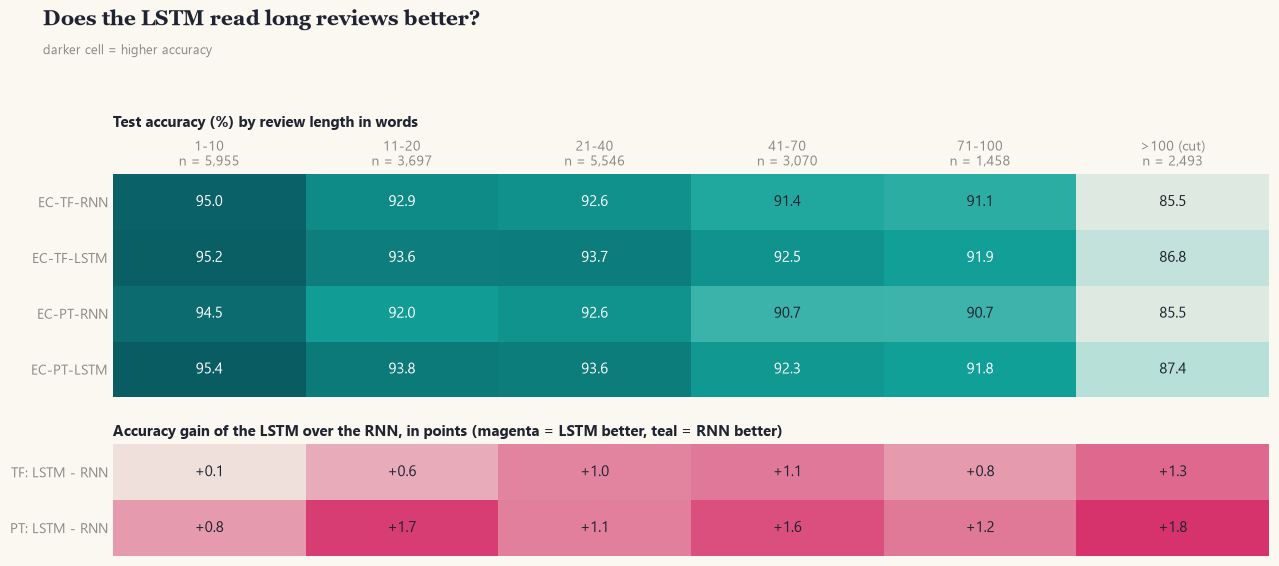

In [21]:
n_te = df.n_words.values[i_te]
bins = [0, 10, 20, 40, 70, 100, 10_000]; labels = ["1-10", "11-20", "21-40", "41-70", "71-100", ">100 (cut)"]
bucket = pd.cut(n_te, bins, labels=labels)
acc_len = pd.DataFrame({k: pd.Series((v["p_test"] >= 0.5) == yte).groupby(bucket).mean() for k, v in RUNS.items()})
acc_len["reviews"] = pd.Series(bucket).value_counts().reindex(labels).values
display(acc_len.round(3))

fig = plt.figure(figsize=(12.5, 6.2)); gs = fig.add_gridspec(2, 1, height_ratios=[4, 2], hspace=0.28)
a = fig.add_subplot(gs[0]); Mx = acc_len[list(RUNS)].T.values
a.imshow(Mx, cmap=SEQ, aspect="auto", vmin=Mx.min() - 0.01, vmax=Mx.max())
for (i, j), val in np.ndenumerate(Mx): a.text(j, i, f"{100 * val:.1f}", ha="center", va="center", fontsize=10.5, color="white" if val > Mx.min() + 0.6 * (Mx.max() - Mx.min()) else C["ink"])
a.set_yticks(range(len(RUNS)), list(RUNS)); a.set_xticks(range(len(labels)), [f"{l}\nn = {n:,}" for l, n in zip(labels, acc_len.reviews)]); a.xaxis.tick_top()
a.set_title("Test accuracy (%) by review length in words", pad=34)
G = np.array([100 * (acc_len[f"EC-{fw}-LSTM"] - acc_len[f"EC-{fw}-RNN"]).values for fw in ("TF", "PT")])
b = fig.add_subplot(gs[1]); b.imshow(G, cmap=DUO, aspect="auto", vmin=-np.abs(G).max(), vmax=np.abs(G).max())
for (i, j), val in np.ndenumerate(G): b.text(j, i, f"{val:+.1f}", ha="center", va="center", fontsize=10.5)
b.set_yticks([0, 1], ["TF: LSTM - RNN", "PT: LSTM - RNN"]); b.set_xticks([]); b.set_title("Accuracy gain of the LSTM over the RNN, in points (magenta = LSTM better, teal = RNN better)")
headline(fig, "Does the LSTM read long reviews better?", "darker cell = higher accuracy")
finish(fig, "EC_by_length", top_in=1.7)

**Reading the length tables.** Looking at the top table, accuracy falls with length for every model: from about 95 % on reviews of 1–10 words to about 85–87 % on reviews over 100 words. Long reviews are harder for everyone, partly because they are cut at 100 words, partly because they contain mixed opinions. The lower table shows the LSTM ahead of the RNN in every bucket, and the advantage is smallest where we expect no memory problem at all: 0.2 points (Keras) in the shortest bucket against 1.3 points in the longest, and 0.9 against 1.9 in PyTorch. So the direction is the one the theory predicts, a gain that grows with length, but the trend is modest and not perfectly smooth (for example, in Keras the gain is 1.1 points at 21–40 words and 0.8 at 71–100). The right reading is that the LSTM helps a little everywhere and somewhat more on long reviews, not that the RNN fails on them.

### How confident are the models?

A model can be right for the wrong reason, and two models with the same accuracy can differ in how sure they are. For every test review the violins below show the **log-odds the model gave to the true class**, $\ln\frac{p}{1-p}$ where $p$ is the probability assigned to the correct label. Above the black line the model was right, below it wrong, and the further from the line the more confident it was. The left half of each violin is the negative reviews, the right half the positive ones.

EC-TF-RNN on negative reviews: median log-odds of the true class 3.3; wrong 11.4 %; wrong with p(true class) below 2 % 1.4 %; right with p(true class) above 98 % 37.8 %
EC-TF-RNN on positive reviews: median log-odds of the true class 5.3; wrong 6.2 %; wrong with p(true class) below 2 % 0.4 %; right with p(true class) above 98 % 70.1 %
EC-TF-LSTM on negative reviews: median log-odds of the true class 3.2; wrong 13.1 %; wrong with p(true class) below 2 % 0.9 %; right with p(true class) above 98 % 30.7 %
EC-TF-LSTM on positive reviews: median log-odds of the true class 4.9; wrong 4.4 %; wrong with p(true class) below 2 % 0.3 %; right with p(true class) above 98 % 68.5 %
EC-PT-RNN on negative reviews: median log-odds of the true class 2.0; wrong 18.2 %; wrong with p(true class) below 2 % 1.1 %; right with p(true class) above 98 % 13.3 %
EC-PT-RNN on positive reviews: median log-odds of the true class 4.6; wrong 3.9 %; wrong with p(true class) below 2 % 0.1 %; right with p(true class) above

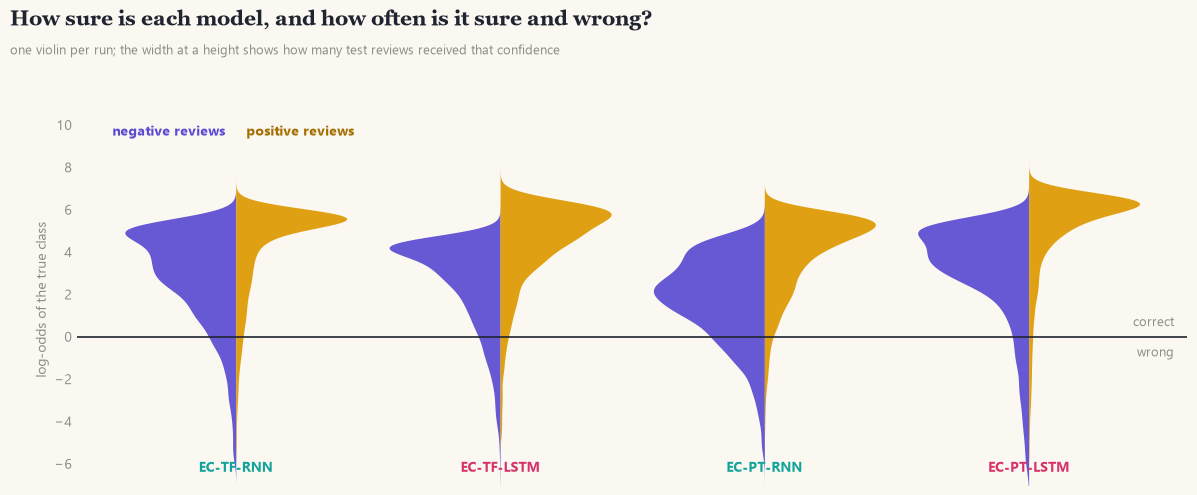

In [22]:
from scipy.stats import gaussian_kde
fig, ax = plt.subplots(figsize=(12, 5.4)); rng = np.random.default_rng(1); grid = np.linspace(-9, 9, 300); stats = []
for j, (k, v) in enumerate(RUNS.items()):
    p = np.clip(v["p_test"], 1e-4, 1 - 1e-4); logit = np.log(p / (1 - p)); margin = np.where(yte == 1, logit, -logit)
    for side, sel, col in [(-1, yte == 0, C["neg"]), (1, yte == 1, C["pos"])]:
        m = margin[sel]; stats.append((k, "negative" if side < 0 else "positive", np.median(m), 100 * np.mean(m < 0), 100 * np.mean(m < -4), 100 * np.mean(m > 4))); d = gaussian_kde(rng.choice(m, size=min(8000, len(m)), replace=False), bw_method=0.2)(grid); d = d / d.max() * 0.42
        ax.fill_betweenx(grid, j, j + side * d, color=col, alpha=0.92, lw=0)
    ax.text(j, -5.9, k, ha="center", va="top", fontweight="bold", color=style(k)["color"])
for k, cls, med, wrong, sure_wrong, sure_right in stats:
    print(f"{k} on {cls} reviews: median log-odds of the true class {med:.1f}; wrong {wrong:.1f} %; wrong with p(true class) below 2 % {sure_wrong:.1f} %; right with p(true class) above 98 % {sure_right:.1f} %")
ax.axhline(0, color=C["ink"], lw=1.2); ax.text(len(RUNS) - 0.45, 0.5, "correct", ha="right", fontsize=9, color=C["mute"]); ax.text(len(RUNS) - 0.45, -0.5, "wrong", ha="right", va="top", fontsize=9, color=C["mute"])
ax.text(-0.04, 9.5, "negative reviews", ha="right", color=C["neg"], fontweight="bold"); ax.text(0.04, 9.5, "positive reviews", ha="left", color="#a36f00", fontweight="bold")
ax.set_ylim(-7, 10.5); ax.set_xlim(-0.6, len(RUNS) - 0.4); ax.set_xticks([]); ax.set_ylabel("log-odds of the true class")
headline(fig, "How sure is each model, and how often is it sure and wrong?", "one violin per run; the width at a height shows how many test reviews received that confidence")
finish(fig, "EC_confidence")

**Reading the violins.** The violin of a run is wide where many reviews received that confidence. The log-odds scale makes the numbers easy to translate: 0 is a coin toss, 2 means a probability of 0.88 for the true class, 3 means 0.95, 4.6 means 0.99. The right halves (positive reviews) lie higher than the left halves (negative reviews) in every run: the median positive review receives log-odds between 4.6 and 5.9 (probability 0.99–0.997), the median negative review only between 2.0 and 3.6 (0.88–0.97). The models are therefore much surer of themselves on praise than on complaints, which fits the fact that complaints are the minority class and are often more varied and longer.

The runs differ in how confident they are, and this does not simply follow their accuracy. The PyTorch RNN is the least sure on negative reviews (median 2.0, only 13 % of them receive more than 98 % for the right class), in line with its high miss rate of 18 %. The PyTorch LSTM is the most confident of all (median 3.6 and 5.9; 41 % of the negative and 82 % of the positive reviews receive more than 98 % for the right class). Confidence has a price: it is also the run with the largest share of negative reviews that it gets wrong *with confidence*, 2.3 % of them with less than 2 % for the true class, compared with 0.9–1.4 % for the Keras runs and 1.1 % for the PyTorch RNN. In the Keras pair the LSTM is somewhat *less* sure than the RNN (30.7 % against 37.8 % of the negative reviews above 98 %) and still more accurate, with fewer confident errors (0.9 % against 1.4 %). Two lessons follow. A higher accuracy does not come from the model being more certain, and a model can be sure and wrong, so a deployed system should not read its probability as a guarantee.


### Example predictions

Numbers hide the actual reviews, so here are some. The table scores the same test reviews with the Keras RNN and the Keras LSTM and shows the first four test reviews and six reviews on which the two models **disagree**. Reading the disagreements is the quickest way to see what the LSTM does differently, and reviews that both models get wrong show the limits of the approach.

In [23]:
pr, pl = RUNS["EC-TF-RNN"]["p_test"], RUNS["EC-TF-LSTM"]["p_test"]
ex = pd.DataFrame({"review": texts[i_te], "stars": df.Rating.values[i_te], "P(pos) RNN": pr.round(3), "P(pos) LSTM": pl.round(3)})
dis = ex[((pr >= 0.5) != (pl >= 0.5))]
print(f"The Keras RNN and the Keras LSTM give different answers on {len(dis):,} of the {len(ex):,} test reviews ({len(dis) / len(ex):.1%}).")
pd.set_option("display.max_colwidth", 160)
display(pd.concat([ex.head(4), dis.sample(min(6, len(dis)), random_state=1)]))

The Keras RNN and the Keras LSTM give different answers on 782 of the 22,219 test reviews (3.5%).


,review,stars,P(pos) RNN,P(pos) LSTM
0,Got this phone for my girlfriend as a Christmas present and she loves it. Tmobile network isn't the best but she's used them for years and has no complaints...,4,0.997,0.999
1,"Seriously, this phone is just 6 weeks old and the audio jack (for earphones) don't work anymore. I haven't dropped it and it's protected by a cover.",1,0.155,0.291
2,"Great case...Bought for my husband as he drops his phone a lot!It gives a great protection, including the screen!!",5,0.996,0.996
3,Nokia was years ahead of the rest with this device and anybody who uses Debian would love it. It may not have many of the modern features and development is...,5,0.981,0.984
18664,I think peoples' expectations at this price point are out of sync. This is a great tablet with LTE and calling abilities for the price. I'm sure the Huawei ...,2,0.473,0.925
7958,I'm changing my review from 4 stars to 2. This Deluxe Edition 128gb does not work with U.S. carriers as advertised and here's why. I bought my wife a 64gb v...,2,0.437,0.649
3666,"I think it was a good phone but my teenage son, who I refer to as ""Butter Fingers,"" broke it after having it only two weeks.",4,0.287,0.534
9387,my father has been having this for like year and a half and there is not problem with this jet.,5,0.360,0.547
10343,"Love the phone, but it drains the battery fairly quickly. Very slick, therefore easy to lose grip. Volume control and screen on/off buttons are opposite one...",4,0.494,0.834
16209,"I ordered a brand new samsung galaxy s4 i9505 but the phone delivered to me is ""used"" one and there are 5 broken crashes in the panel.I am very disappointed...",1,0.669,0.378


**Reading the examples.** The first four rows are the first reviews of the test set, and they show what an easy case looks like: clear praise (4 and 5 stars, probabilities 0.98–1.00 for both models) or a clear complaint (the audio jack that stopped working, 0.16 and 0.29), and both networks agree. The six reviews below them were drawn at random from the 782 on which the two networks give different answers (3.5 % of the test set). On the 22,219 test reviews the LSTM is right on 20,667 and the RNN on 20,497, a difference of 170, so among the 782 disagreements the LSTM must be right on 476 (61 %) and the RNN on 306: the sample of six shows four LSTM wins and two RNN wins, about what we expect.

Reading the reviews explains what kind of text splits the models. Almost all of them are *mixed*. "Love the phone, but it drains the battery" (4 stars), "I think it was a good phone but my teenage son … broke it" (4 stars) and "there is not problem with this jet" (5 stars) start or end with praise, or use a negation, and the RNN, which relies on the last words it read, is swayed by the complaint-like words (*drains*, *broke*, *not problem*) and answers negative (0.49, 0.29, 0.36), whereas the LSTM keeps the earlier verdict and answers positive (0.83, 0.53, 0.55). The negation case is the one in which we expected a model with a memory to help, and it does, although the 0.53 and 0.55 show how narrow the margin is. The Samsung buyer who received a "used" phone (1 star) is a negative review that begins with neutral product details and ends with *very disappointed*; here the LSTM is right (0.38) and the RNN wrong (0.67).

The two remaining reviews are LSTM mistakes, and they are instructive. The tablet review ("expectations at this price point are out of sync. This is a great tablet …") carries 2 stars but reads as praise; the LSTM's 0.93 is a defensible reading of the text and the label is the questionable part. The reviewer who is "changing my review from 4 stars to 2" starts with a rating and a product description before the complaint; the early, neutral content outweighs the later complaint in the LSTM (0.65), while the RNN, reading the end, gets it right (0.44). These are the reviews at which any model is in trouble: the star rating and the text disagree, or the verdict is spread over a long text.


## 8. Conclusion

**What we did.** We turned 148,124 labelled Amazon reviews into sequences of at most 100 word ids and trained four networks of identical shape, a 5-layer RNN and a 5-layer LSTM in Keras and in PyTorch, with the same data, the same starting weights and the same training recipe, and compared them with two baselines on 22,219 unseen test reviews.

**What we found.**

1. **The LSTM beats the RNN, in both frameworks.** Accuracy rises by 0.8 points (Keras) and 1.3 points (PyTorch), the F1 of the negative class by 0.9 and 2.7 points, and the ROC-AUC from 0.971 to 0.975 and from 0.968 to 0.976. The two libraries agree with each other much better than the RNN agrees with the LSTM, so the effect belongs to the architecture.
2. **The advantage grows, modestly, with review length.** On reviews of up to 10 words the two models are nearly tied in Keras (0.950 against 0.952); on reviews of more than 100 words the LSTM leads by 1.3 points (Keras) and 1.9 points (PyTorch). This is the direction predicted by the vanishing-gradient argument of the concepts notebook, but the trend is not smooth and not large.
3. **The simple baseline wins.** TF-IDF + logistic regression, which ignores word order, reaches 0.941 accuracy and 0.983 AUC and is better than all four networks on every headline metric, after 9 seconds of training instead of several minutes. We explain it in three parts. (a) The signal in these reviews is mostly lexical: words like *refund*, *defective* and *excellent* decide the label, and a bag of words sees all of them. (b) The networks see only the first 100 words and must learn the 64-dimensional embedding of 20,000 words from 104,000 reviews, which is why they overfit after two or three epochs, whereas the linear model has no such problem. (c) We gave the networks no regularisation or pretrained word vectors, to keep the experiment about the architectures.
4. **The LSTM is a more expensive choice.** It needs 2.2 to 4.6 times as long per epoch on a CPU and has about 9 % more parameters in total (four times more in the recurrent layers).

**When is the LSTM worth it?** On this task the extra cost buys one or two points of accuracy and a larger gain on long, wordy negative reviews, which are the ones a shop cares about, but not enough to beat a well-tuned bag-of-words model. A sensible practitioner would start with TF-IDF, and reach for an LSTM when word order really matters or when other inputs have to be combined with the text.

**Limitations.** Each configuration was trained once, so differences of a few tenths of a point (such as the 0.1-point gap between the Keras and PyTorch LSTMs) are within run-to-run noise; reviews were cut at 100 words; the embeddings were learned from scratch; no dropout or other regularisation was used; the hyperparameters were not tuned separately for each model; and the timings are CPU timings on one machine.

**What to try next.** Pretrained word vectors (they would remove the overfitting of the embedding), a bidirectional LSTM or a GRU, an attention layer, dropout, several seeds per configuration to measure the noise, and a comparison on a data set where the evidence for the label is spread over much longer texts. The numbers quoted above come from the run recorded in §7; the report uses the same tables.